# Exploratory Data Analysis on Retail Transaction Data
**NextHikes IT Solutions**
This notebook explores 100,000 retail orders (18 columns): how each column behaves, how the columns relate to each other, and what stands out in the data.
## Table of Contents
1. Introduction
2. Load the Dataset
3. Understand the Dataset and Its Columns
4. Data Cleaning and Preprocessing
5. Univariate Analysis – Numerical Variables
6. Univariate Analysis – Categorical Variables
7. Outlier Detection and Capping
8. Bivariate Analysis – Numerical vs. Numerical
9. Bivariate Analysis – Numerical vs. Categorical
10. Bivariate Analysis – Categorical vs. Categorical
11. Multivariate Analysis
12. Additional Analysis
13. Key Findings and Insights
14. Conclusion

## 1. Import Libraries and Load the Data
Import the libraries and take a first look at the dataset.

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:,.2f}".format)

# folder where the charts will be saved
os.makedirs("outputs/figures", exist_ok=True)

In [2]:
retail_data_raw = pd.read_csv("data/Original_dataset.csv")
print("Rows:", retail_data_raw.shape[0], "| Columns:", retail_data_raw.shape[1])
retail_data_raw.head()

Rows: 100000 | Columns: 18


,customer_id,age,gender,city,state,customer_segment,order_id,order_date,product_category,product_subcategory,product_price,quantity,discount_percentage,final_price,payment_method,shipping_type,delivery_days,return_status
0,C10000,56,Male,Hyderabad,Telangana,New,O50000,2025-05-10,Health,Protein Powder,38658,3,7,"107,855.82",Debit Card,Standard,5,No
1,C10001,36,Male,Pune,Maharashtra,Premium,O50001,2023-11-27,Electronics,Smartphone,22462,4,20,"71,878.40",Cash on Delivery,Standard,4,Yes
2,C10002,20,Male,Kolkata,West Bengal,New,O50002,2025-02-08,Fashion,Women Dress,56601,2,27,"82,637.46",Credit Card,Standard,5,No
3,C10003,39,Female,Jaipur,Rajasthan,New,O50003,2024-04-19,Beauty,Perfume,26158,3,9,"71,411.34",UPI,Standard,3,No
4,C10004,20,Male,Chennai,Tamil Nadu,Premium,O50004,2024-10-08,Beauty,Shampoo,31240,1,6,"29,365.60",UPI,Standard,2,No


In [3]:
retail_data_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 18 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   customer_id          100000 non-null  str    
 1   age                  100000 non-null  int64  
 2   gender               100000 non-null  str    
 3   city                 100000 non-null  str    
 4   state                100000 non-null  str    
 5   customer_segment     100000 non-null  str    
 6   order_id             100000 non-null  str    
 7   order_date           100000 non-null  str    
 8   product_category     100000 non-null  str    
 9   product_subcategory  100000 non-null  str    
 10  product_price        100000 non-null  int64  
 11  quantity             100000 non-null  int64  
 12  discount_percentage  100000 non-null  int64  
 13  final_price          100000 non-null  float64
 14  payment_method       100000 non-null  str    
 15  shipping_type        100000 n

In [4]:
retail_data_raw.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customer_id,100000,100000,C10000,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,"100,000.00",NaN,NaN,NaN,41.56,13.85,18.00,30.00,42.00,54.00,65.00
gender,100000,2,Male,50111,NaN,NaN,NaN,NaN,NaN,NaN,NaN
city,100000,10,Hyderabad,10150,NaN,NaN,NaN,NaN,NaN,NaN,NaN
state,100000,9,Maharashtra,19952,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_segment,100000,3,New,33488,NaN,NaN,NaN,NaN,NaN,NaN,NaN
order_id,100000,100000,O50000,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
order_date,100000,1095,2023-04-12,124,NaN,NaN,NaN,NaN,NaN,NaN,NaN
product_category,100000,6,Health,16858,NaN,NaN,NaN,NaN,NaN,NaN,NaN
product_subcategory,100000,21,Protein Powder,5668,NaN,NaN,NaN,NaN,NaN,NaN,NaN


**Interpretation:**
- 100,000 rows and 18 columns, with no missing values.
- 12 columns are text, 5 are whole numbers and only `final_price` has decimals.
- `order_date` is stored as text and is converted in section 3.
- `customer_id` and `order_id` are unique, so every row is one customer and one order.
- Age ranges from 18 to 65, price from 500 to 59,998, quantity from 1 to 4, discount from 0 to 30% and delivery from 1 to 10 days.
- Orders are spread over 1,095 different dates.

## 2. Understanding the Columns
Group the columns by type so each one gets a suitable chart and method.

| Column | Meaning |
|---|---|
| customer_id, order_id | ID of the customer and of the order |
| age, gender | Customer age and gender |
| city, state | Where the customer lives |
| customer_segment | New, Regular or Premium customer |
| order_date | Date of the order |
| product_category, product_subcategory | What was bought |
| product_price | Price of one unit |
| quantity | Number of units in the order |
| discount_percentage | Discount given (%) |
| final_price | Order amount after discount |
| payment_method, shipping_type | How the customer paid and how the order was shipped |
| delivery_days | Days taken to deliver |
| return_status | Whether the order was returned (Yes/No) |

In [5]:
id_cols = ["customer_id", "order_id"]
date_cols = ["order_date"]
num_cols = ["age", "product_price", "quantity", "discount_percentage", "final_price", "delivery_days"]
cat_cols = ["gender", "city", "state", "customer_segment", "product_category",
            "product_subcategory", "payment_method", "shipping_type", "return_status"]

# number of different values in each column
retail_data_raw.nunique().to_frame("unique_values")

,unique_values
customer_id,100000
age,48
gender,2
city,10
state,9
customer_segment,3
order_id,100000
order_date,1095
product_category,6
product_subcategory,21


**Interpretation:**
- The 18 columns are 2 ID, 1 date, 6 numerical and 9 categorical columns. ID columns are only labels and are left out of the statistics.
- `quantity` (4 values), `delivery_days` (10) and `discount_percentage` (31) are numerical but take only a few whole values, so some charts treat them like groups.
- Every `customer_id` appears once, so repeat buying cannot be studied.
- There are 6 categories, 21 subcategories, 10 cities and 9 states.

## 3. Data Cleaning and Preprocessing
Clean and prepare the dataset so it is consistent, accurate and ready for analysis.

### 3.1 Data Quality Checks
Check column names, text values, missing values and duplicates.

In [6]:
# work on a copy so the original data stays untouched
retail_data = retail_data_raw.copy()

# column names: remove spaces and use lowercase
retail_data.columns = retail_data.columns.str.strip().str.lower()

# text columns: remove extra spaces
extra_spaces = sum((retail_data[col] != retail_data[col].str.strip()).sum() for col in id_cols + cat_cols)
for col in id_cols + cat_cols:
    retail_data[col] = retail_data[col].str.strip()

print("Column names with spaces or special characters:", [c for c in retail_data_raw.columns if not c.replace("_", "").isalnum()])
print("Text values with extra spaces:", extra_spaces)
print("Missing values:", retail_data.isnull().sum().sum())
print("Duplicate rows:", retail_data.duplicated().sum())
print("Repeated order_id:", retail_data["order_id"].duplicated().sum(), "| Repeated customer_id:", retail_data["customer_id"].duplicated().sum())
print()

# same value written in different ways? (e.g. "male" and "Male")
for col in ["gender", "customer_segment", "product_category", "payment_method", "shipping_type", "return_status"]:
    print(col, "->", list(retail_data[col].unique()))

Column names with spaces or special characters: []
Text values with extra spaces: 0
Missing values: 0
Duplicate rows: 0
Repeated order_id: 0 | Repeated customer_id: 0

gender -> ['Male', 'Female']
customer_segment -> ['New', 'Premium', 'Regular']
product_category -> ['Health', 'Electronics', 'Fashion', 'Beauty', 'Grocery', 'Home & Kitchen']
payment_method -> ['Debit Card', 'Cash on Delivery', 'Credit Card', 'UPI']
shipping_type -> ['Standard', 'Express']
return_status -> ['No', 'Yes']


**Interpretation:**
- Column names are clean: no spaces, special characters or duplicates.
- No extra spaces and no spelling variants in the categories. The "&" in Home & Kitchen and the "-" in Men T-Shirt are part of the real names.
- No missing values, no duplicate rows and no repeated `order_id` or `customer_id`.
- No rows had to be removed or filled, so all 100,000 rows are used.

### 3.2 Data Types and Validation
Convert `order_date` to a date type and check that all values are valid.

In [7]:
retail_data["order_date"] = pd.to_datetime(retail_data["order_date"])
print("Order dates:", retail_data["order_date"].min().date(), "to", retail_data["order_date"].max().date())

# valid ranges
display(retail_data[["age", "product_price", "quantity", "discount_percentage", "delivery_days"]].agg(["min", "max"]).T.astype(int))

# is final_price = price x quantity x (1 - discount)?
calculated_price = retail_data["product_price"] * retail_data["quantity"] * (1 - retail_data["discount_percentage"] / 100)
difference = (calculated_price - retail_data["final_price"]).abs()
print("Rows where final_price does not match the formula:", (difference > 0.01).sum())

# one state for each city, one category for each subcategory?
print("Cities with more than one state:", (retail_data.groupby("city")["state"].nunique() > 1).sum())
print("Subcategories with more than one category:", (retail_data.groupby("product_subcategory")["product_category"].nunique() > 1).sum())

Order dates: 2023-01-01 to 2025-12-30


,min,max
age,18,65
product_price,500,59998
quantity,1,4
discount_percentage,0,30
delivery_days,1,10


Rows where final_price does not match the formula: 0
Cities with more than one state: 0
Subcategories with more than one category: 0


**Interpretation:**
- `order_date` is converted successfully. Orders run from 1 January 2023 to 30 December 2025, about three years.
- All values are in valid ranges (age 18 to 65, price 500 to 59,998, quantity 1 to 4, discount 0 to 30%, delivery 1 to 10 days).
- `final_price` equals price x quantity x (1 - discount) in every row. It is a calculated column, so its strong link with those three columns later is expected from the formula and is not a new finding.
- Every city belongs to one state and every subcategory to one category.

### 3.3 New Columns
Add date parts, order amounts, a return flag, and age, discount and delivery groups.

In [8]:
retail_data["order_year"] = retail_data["order_date"].dt.year
retail_data["order_month"] = retail_data["order_date"].dt.month
retail_data["weekday"] = retail_data["order_date"].dt.day_name()

retail_data["gross_amount"] = retail_data["product_price"] * retail_data["quantity"]
retail_data["discount_amount"] = retail_data["gross_amount"] - retail_data["final_price"]
retail_data["revenue_per_unit"] = retail_data["final_price"] / retail_data["quantity"]
retail_data["is_return"] = (retail_data["return_status"] == "Yes").astype(int)

retail_data["age_group"] = pd.cut(retail_data["age"], bins=[17, 25, 35, 45, 55, 65],
                                  labels=["18-25", "26-35", "36-45", "46-55", "56-65"])
retail_data["discount_band"] = pd.cut(retail_data["discount_percentage"], bins=[-1, 5, 10, 15, 20, 25, 30],
                                      labels=["0-5%", "6-10%", "11-15%", "16-20%", "21-25%", "26-30%"])
retail_data["delivery_speed"] = pd.cut(retail_data["delivery_days"], bins=[0, 3, 6, 10],
                                       labels=["Fast (1-3 days)", "Medium (4-6 days)", "Slow (7-10 days)"])

print("Shape now:", retail_data.shape)
retail_data[["order_date", "weekday", "gross_amount", "discount_amount", "revenue_per_unit",
             "is_return", "age_group", "discount_band", "delivery_speed"]].head()

Shape now: (100000, 28)


,order_date,weekday,gross_amount,discount_amount,revenue_per_unit,is_return,age_group,discount_band,delivery_speed
0,2025-05-10,Saturday,115974,"8,118.18","35,951.94",0,56-65,6-10%,Medium (4-6 days)
1,2023-11-27,Monday,89848,"17,969.60","17,969.60",1,36-45,16-20%,Medium (4-6 days)
2,2025-02-08,Saturday,113202,"30,564.54","41,318.73",0,18-25,26-30%,Medium (4-6 days)
3,2024-04-19,Friday,78474,"7,062.66","23,803.78",0,36-45,6-10%,Fast (1-3 days)
4,2024-10-08,Tuesday,31240,"1,874.40","29,365.60",0,18-25,6-10%,Fast (1-3 days)


**Interpretation:**
- 10 columns are added, so the data goes from 18 to 28 columns (two more are added in section 6).
- Every row received an age group, a discount band and a delivery speed.
- The 0-5% discount band covers six values and the other bands five, so it has a few more orders.

## 4. Univariate Analysis: Numerical Columns
Study each numerical column on its own: summary statistics, shape and spread.

Skewness near 0 means balanced data and a positive value means a long right tail. Excess kurtosis near 0 means a bell-like shape, a negative value a flat shape and a large positive value heavy tails.

### 4.1 Summary Statistics

In [9]:
summary = retail_data[num_cols].describe().T
summary["median"] = retail_data[num_cols].median()
summary["skewness"] = retail_data[num_cols].skew()
summary["kurtosis"] = retail_data[num_cols].kurt()
summary = summary[["mean", "median", "std", "min", "max", "skewness", "kurtosis"]]
summary

,mean,median,std,min,max,skewness,kurtosis
age,41.56,42.00,13.85,18.00,65.00,-0.00,-1.20
product_price,"30,164.53","30,148.00","17,139.68",500.00,"59,998.00",0.00,-1.20
quantity,2.50,3.00,1.12,1.00,4.00,-0.00,-1.36
discount_percentage,15.01,15.00,8.95,0.00,30.00,-0.00,-1.20
final_price,"64,165.72","49,752.39","49,969.28",357.00,"239,980.00",0.93,0.17
delivery_days,5.51,5.00,2.87,1.00,10.00,0.00,-1.22


### 4.2 Histograms
Histograms show the shape and spread of each column. Dashed line: mean. Dotted line: median.

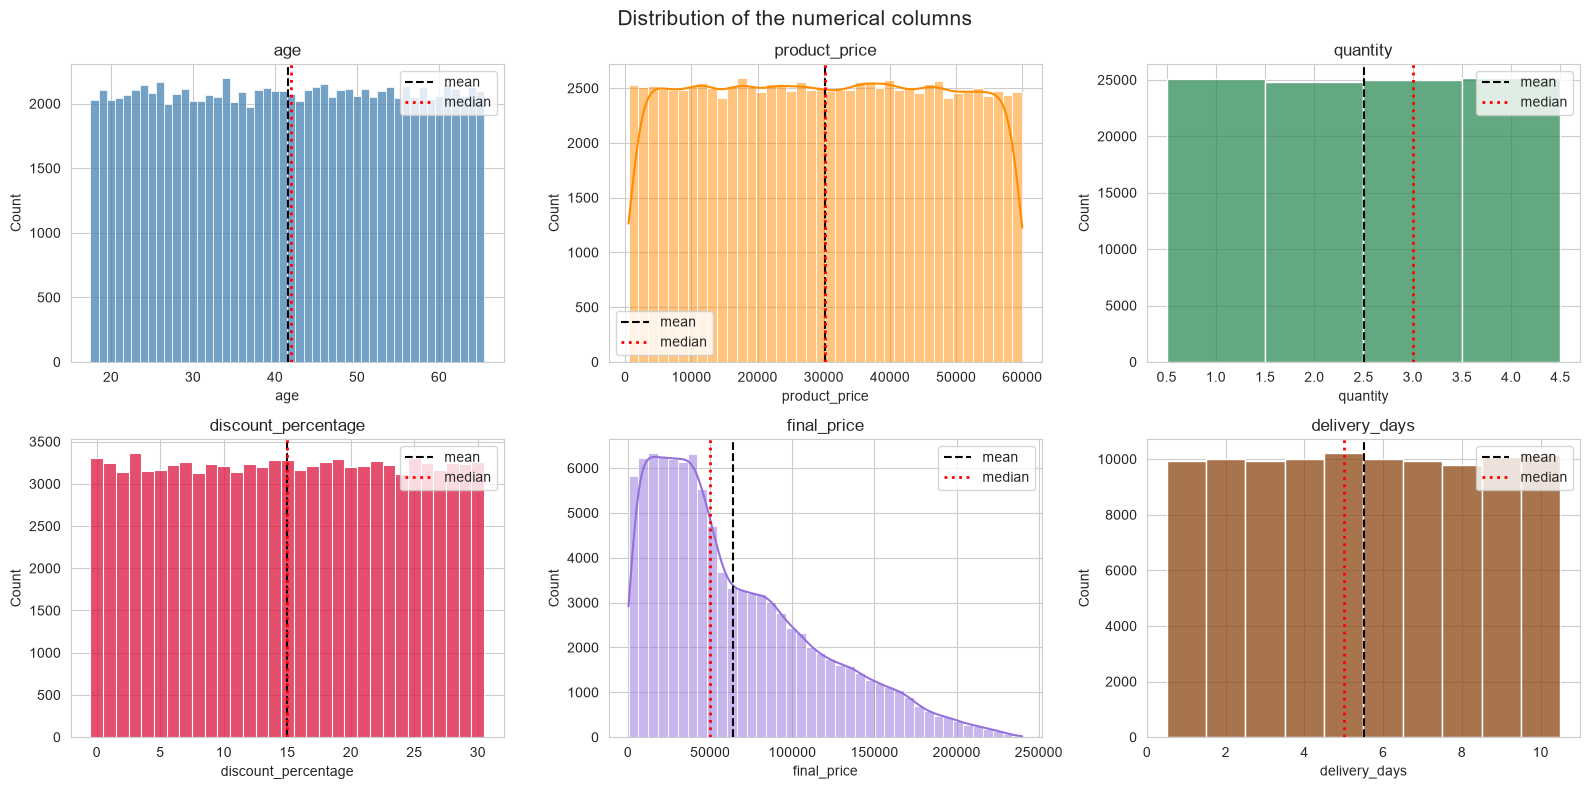

In [10]:
colors = ["steelblue", "darkorange", "seagreen", "crimson", "mediumpurple", "saddlebrown"]

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col, color in zip(axes.flatten(), num_cols, colors):
    if retail_data[col].nunique() < 60:
        # columns with only a few whole numbers: one bar for each value
        sns.histplot(retail_data[col], discrete=True, color=color, ax=ax)
    else:
        sns.histplot(retail_data[col], bins=40, kde=True, color=color, ax=ax)
    ax.axvline(retail_data[col].mean(), color="black", linestyle="--", label="mean")
    ax.axvline(retail_data[col].median(), color="red", linestyle=":", linewidth=2, label="median")
    ax.set_title(col)
    ax.legend()

plt.suptitle("Distribution of the numerical columns", fontsize=15)
plt.tight_layout()
plt.savefig("outputs/figures/01_histograms.png", bbox_inches="tight")
plt.show()

### 4.3 Boxplots
Boxplots show the spread of each column and mark outliers as points beyond the whiskers.

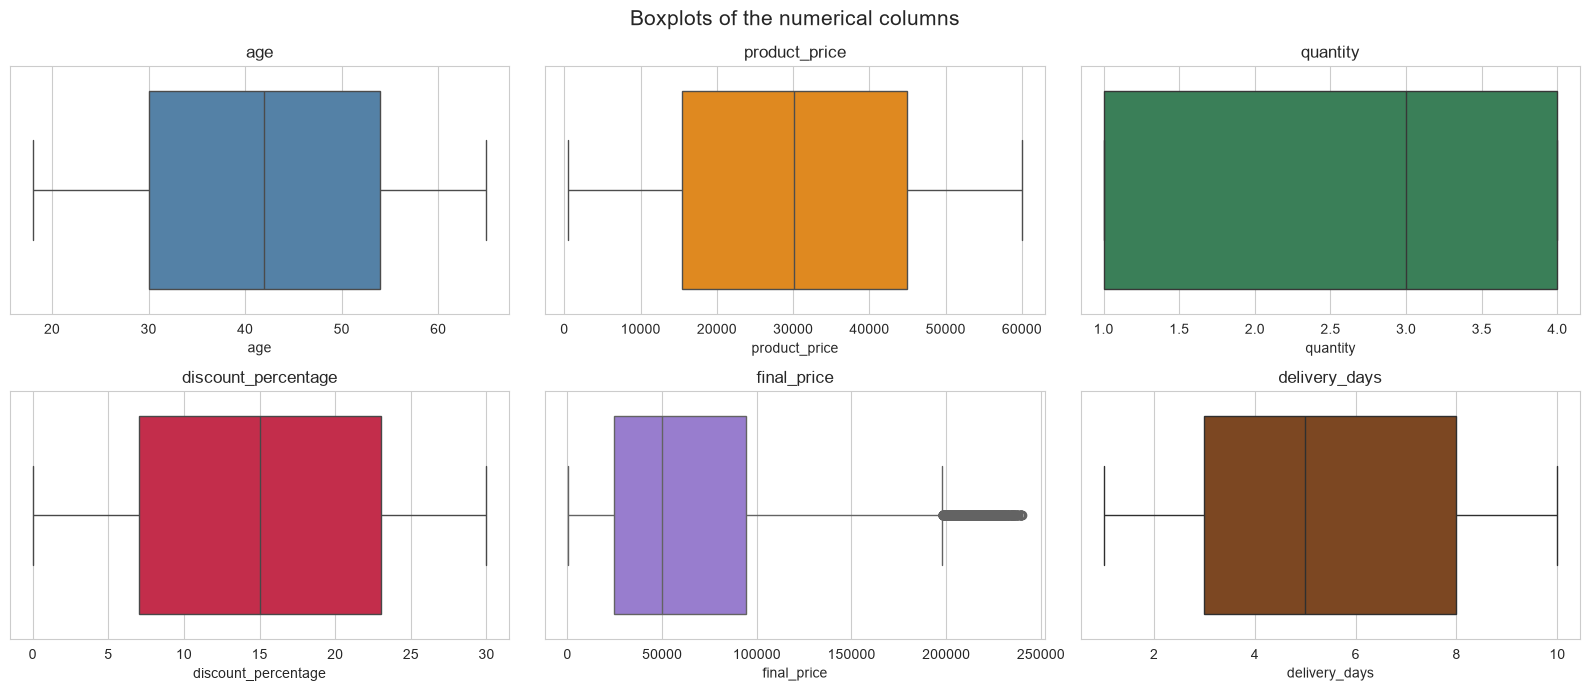

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(16, 7))
for ax, col, color in zip(axes.flatten(), num_cols, colors):
    sns.boxplot(x=retail_data[col], color=color, ax=ax)
    ax.set_title(col)

plt.suptitle("Boxplots of the numerical columns", fontsize=15)
plt.tight_layout()
plt.savefig("outputs/figures/02_boxplots.png", bbox_inches="tight")
plt.show()

**Interpretation:**
- `age`, `product_price`, `quantity`, `discount_percentage` and `delivery_days` have flat histograms: skewness is about 0, mean is close to median and kurtosis is about -1.2 (-1.36 for `quantity`). Every value is almost equally common, for example about 25% of orders for each quantity and about 10% for each delivery day.
- `product_price` is not right-skewed. Cheap and expensive products are equally common.
- `final_price` is right-skewed (0.93): mean 64,166, median 49,752, maximum 239,980. It is built by multiplying price, quantity and discount.
- Kurtosis of `final_price` is 0.17, so the tail is long but has no extreme spikes.
- Only `final_price` has points beyond the whiskers, all on the right side. They are examined in section 6.

## 5. Univariate Analysis: Categorical Columns
Count the orders in each category of every categorical column.

### 5.1 Frequency Tables

In [12]:
for col in ["gender", "customer_segment", "product_category", "payment_method", "shipping_type", "return_status"]:
    print(col)
    display(retail_data[col].value_counts(normalize=True).mul(100).round(2).to_frame("percent"))

print("Overall return rate:", round(retail_data["is_return"].mean() * 100, 2), "%")

gender


,percent
gender,
Male,50.11
Female,49.89


customer_segment


,percent
customer_segment,
New,33.49
Regular,33.36
Premium,33.15


product_category


,percent
product_category,
Health,16.86
Home & Kitchen,16.85
Fashion,16.61
Grocery,16.59
Electronics,16.58
Beauty,16.51


... (3 outputs left out)

,percent
shipping_type,
Express,50.01
Standard,49.99


return_status


,percent
return_status,
No,85.19
Yes,14.81


Overall return rate: 14.81 %


### 5.2 Count Plots
Each chart uses its own colours.

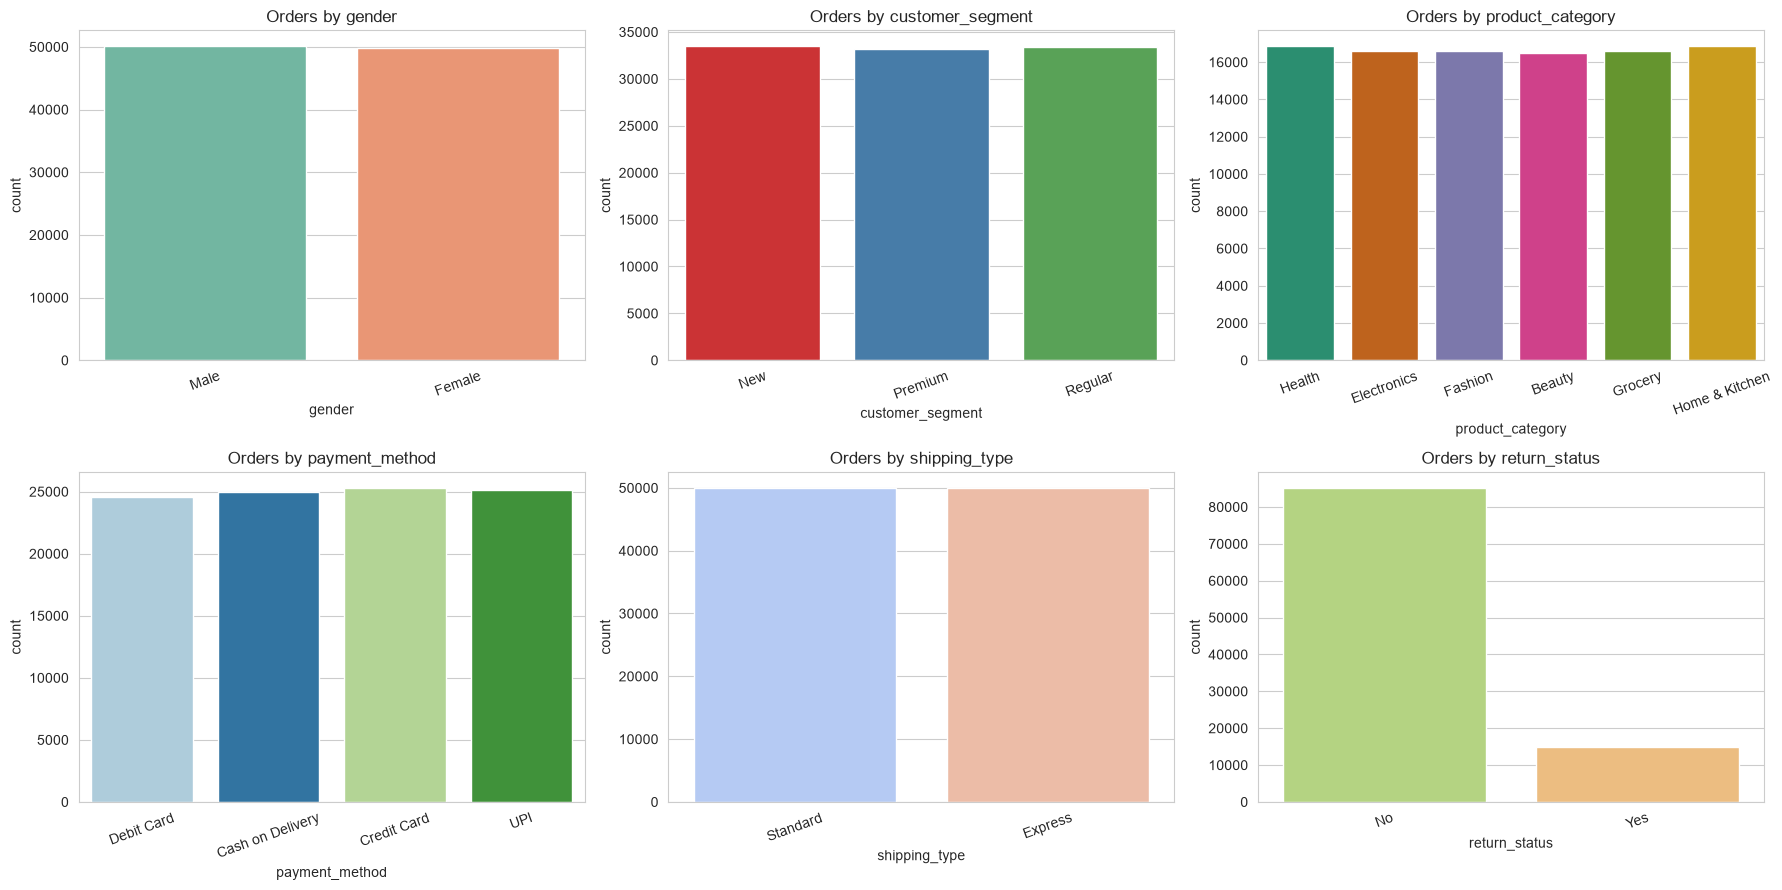

In [13]:
plot_cols = ["gender", "customer_segment", "product_category", "payment_method", "shipping_type", "return_status"]
palettes = ["Set2", "Set1", "Dark2", "Paired", "coolwarm", "RdYlGn_r"]

fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for ax, col, palette in zip(axes.flatten(), plot_cols, palettes):
    sns.countplot(data=retail_data, x=col, hue=col, palette=palette, legend=False, ax=ax)
    ax.set_title("Orders by " + col)
    ax.tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.savefig("outputs/figures/03_countplots.png", bbox_inches="tight")
plt.show()

### 5.3 City and State

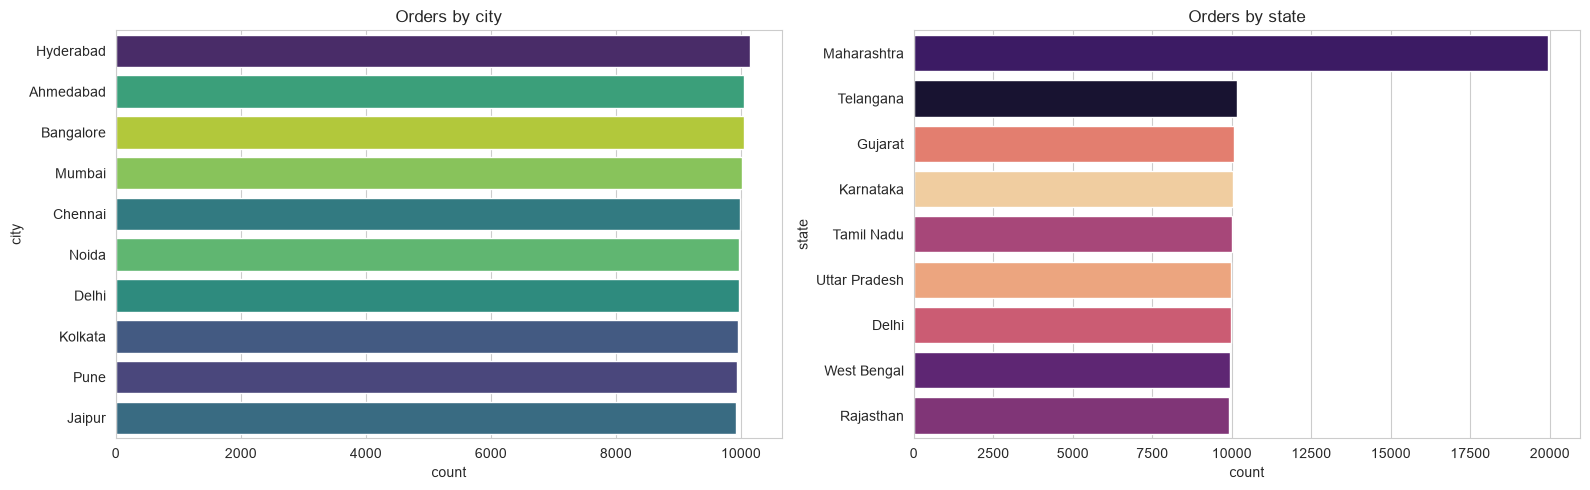

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

city_order = retail_data["city"].value_counts().index
sns.countplot(data=retail_data, y="city", hue="city", order=city_order, palette="viridis", legend=False, ax=axes[0])
axes[0].set_title("Orders by city")

state_order = retail_data["state"].value_counts().index
sns.countplot(data=retail_data, y="state", hue="state", order=state_order, palette="magma", legend=False, ax=axes[1])
axes[1].set_title("Orders by state")

plt.tight_layout()
plt.savefig("outputs/figures/04_city_state.png", bbox_inches="tight")
plt.show()

### 5.4 Subcategories and Customer Segments
Left chart: colour shows the category of each subcategory. Right chart: colour shows the customer segment.

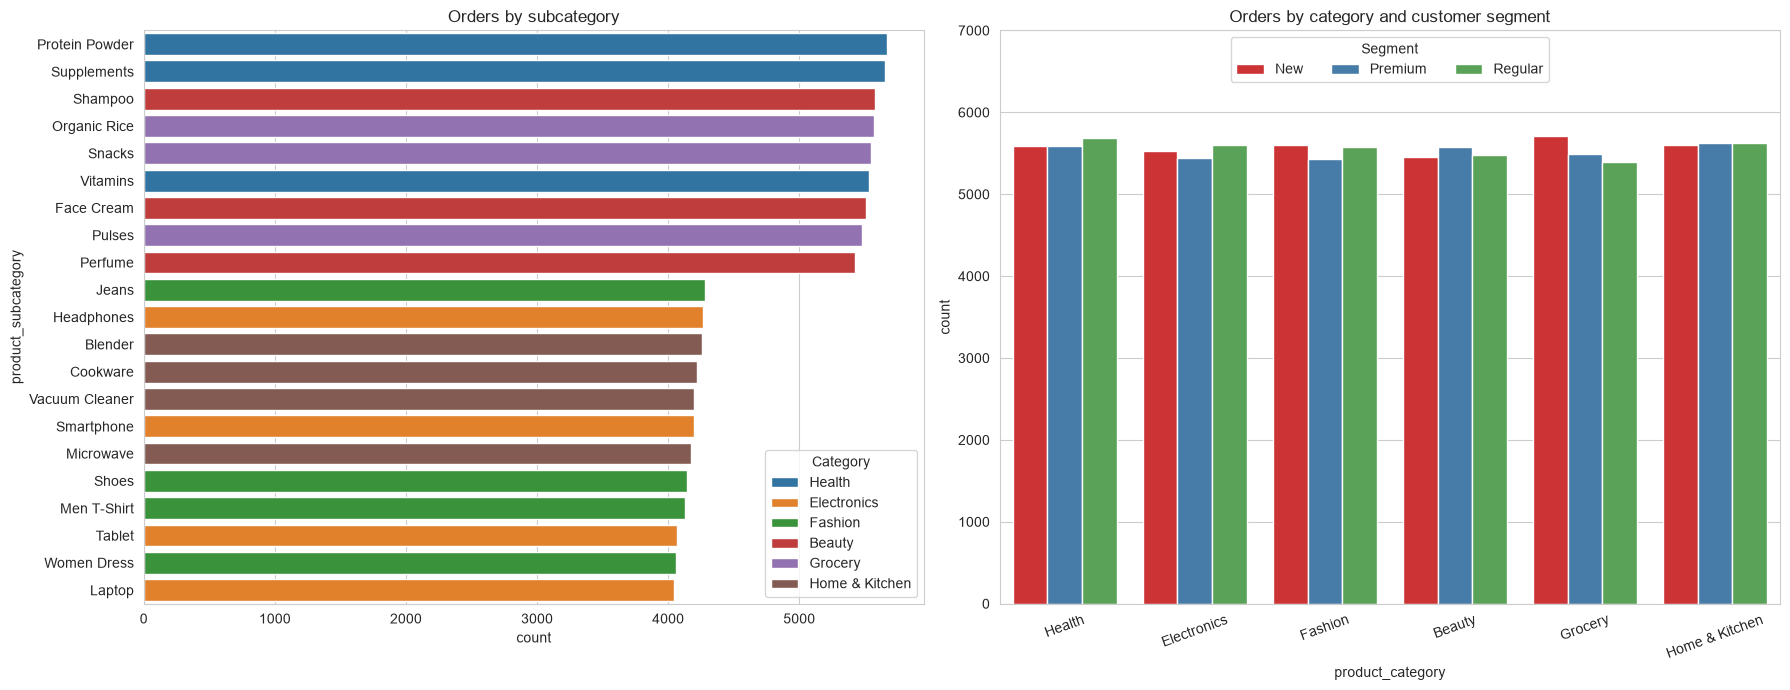

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

sub_order = retail_data["product_subcategory"].value_counts().index
sns.countplot(data=retail_data, y="product_subcategory", hue="product_category", order=sub_order,
              dodge=False, palette="tab10", ax=axes[0])
axes[0].set_title("Orders by subcategory")
axes[0].legend(title="Category", loc="lower right")

sns.countplot(data=retail_data, x="product_category", hue="customer_segment", palette="Set1", ax=axes[1])
axes[1].set_title("Orders by category and customer segment")
axes[1].tick_params(axis="x", rotation=20)
axes[1].set_ylim(0, 7000)
axes[1].legend(title="Segment", ncol=3, loc="upper center")

plt.tight_layout()
plt.savefig("outputs/figures/05_subcategory_segment.png", bbox_inches="tight")
plt.show()

### 5.5 Donut Charts

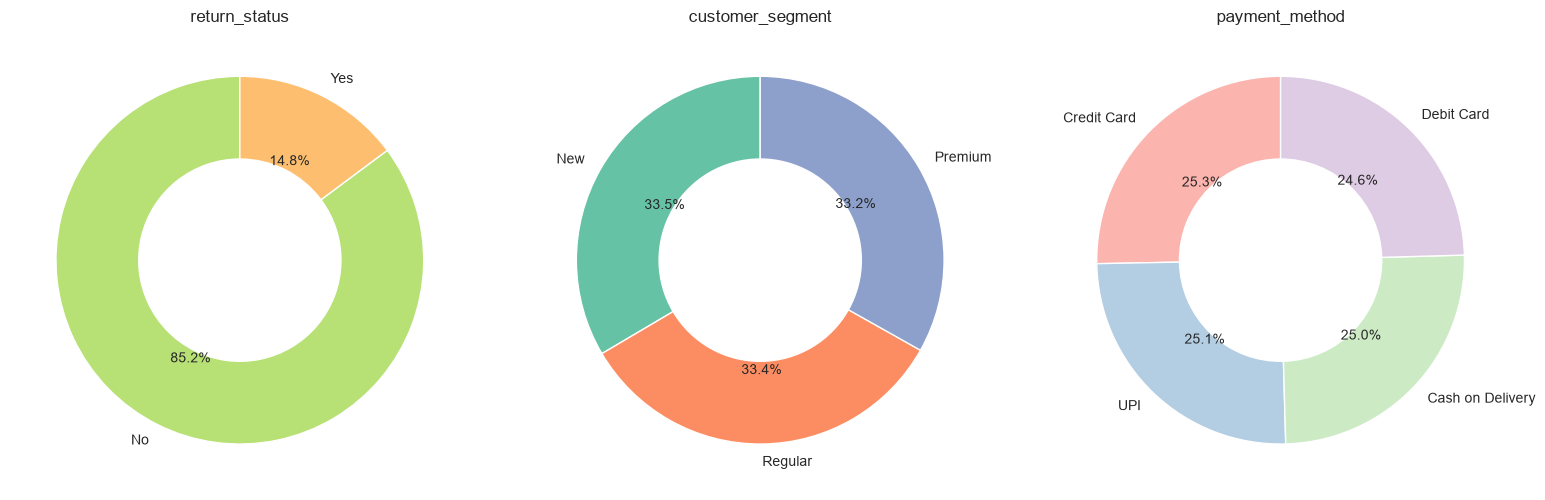

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, col, palette in zip(axes, ["return_status", "customer_segment", "payment_method"], ["RdYlGn_r", "Set2", "Pastel1"]):
    counts = retail_data[col].value_counts()
    ax.pie(counts.values, labels=counts.index, autopct="%1.1f%%", startangle=90,
           colors=sns.color_palette(palette, len(counts)), wedgeprops=dict(width=0.45, edgecolor="white"))
    ax.set_title(col)

plt.tight_layout()
plt.savefig("outputs/figures/06_donut_charts.png", bbox_inches="tight")
plt.show()

**Interpretation:**
- The data is very balanced: gender 50.1% and 49.9%, segments New 33.5%, Regular 33.4% and Premium 33.2%, each payment method 24.6% to 25.3%, Express and Standard 50% each, and every city about 10%.
- Categories are 16.5% to 16.9% each (Health highest, Beauty lowest), so no category or segment dominates.
- Maharashtra has about 20% of the orders because it has two cities (Mumbai and Pune).
- Health, Grocery and Beauty subcategories have about 5,500 orders each against about 4,200 for the others, because these categories have 3 subcategories and the rest have 4. The categories are equal in size.
- `return_status` is the only unbalanced column: 14.81% of orders (14,811) were returned.
- The three segments have almost the same bar height in every category.

## 6. Outlier Detection and Capping
Find extreme values with the IQR and Z-score methods, check what these orders are, and cap them in a new column.

- IQR method: a value is an outlier if it is below Q1 - 1.5 x IQR or above Q3 + 1.5 x IQR.
- Z-score method: a value is an outlier if it is more than 3 standard deviations from the mean.

### 6.1 Outliers in Each Numerical Column

In [17]:
rows = []
for col in num_cols:
    q1 = retail_data[col].quantile(0.25)
    q3 = retail_data[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    iqr_outliers = ((retail_data[col] < lower) | (retail_data[col] > upper)).sum()

    z_score = (retail_data[col] - retail_data[col].mean()) / retail_data[col].std()
    z_outliers = (z_score.abs() > 3).sum()

    rows.append([col, lower, upper, iqr_outliers, z_outliers])

outlier_table = pd.DataFrame(rows, columns=["column", "lower_limit", "upper_limit", "IQR_outliers", "Zscore_outliers"])
outlier_table.set_index("column")

,lower_limit,upper_limit,IQR_outliers,Zscore_outliers
column,,,,
age,-6.00,90.00,0,0
product_price,"-28,998.00","89,330.00",0,0
quantity,-3.50,8.50,0,0
discount_percentage,-17.00,47.00,0,0
final_price,"-79,306.60","198,057.67",1335,503
delivery_days,-4.50,15.50,0,0


### 6.2 Outlier Orders
Only `final_price` has outliers, so these orders are checked before anything is changed.

Upper limit for final_price: 198057.68
Number of outlier orders: 1335 out of 100000

Average of normal orders and outlier orders:


,quantity,product_price,discount_percentage,final_price
is_outlier,,,,
False,2.48,"29,811.58",15.14,"62,164.67"
True,4.00,"56,249.43",5.65,"212,056.44"


Quantity of the outlier orders:
quantity
4    1335
Name: count, dtype: int64


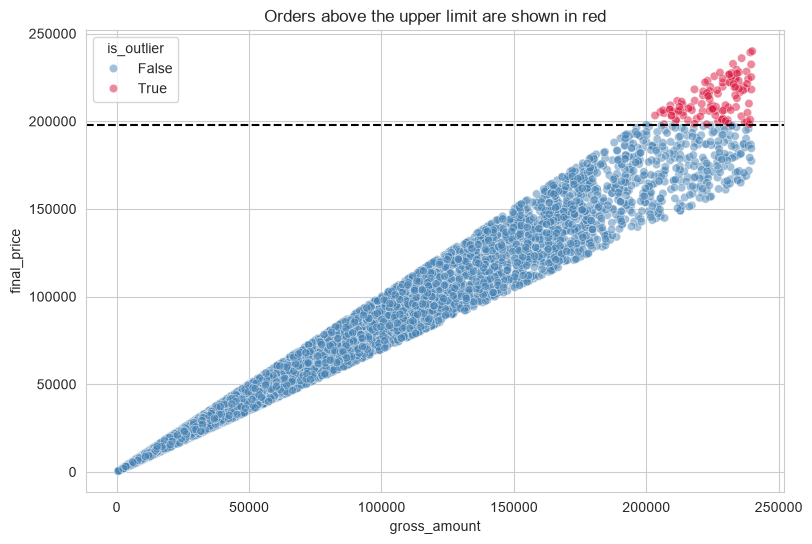

In [18]:
q1 = retail_data["final_price"].quantile(0.25)
q3 = retail_data["final_price"].quantile(0.75)
lower_limit = q1 - 1.5 * (q3 - q1)
upper_limit = q3 + 1.5 * (q3 - q1)

retail_data["is_outlier"] = (retail_data["final_price"] > upper_limit) | (retail_data["final_price"] < lower_limit)
print("Upper limit for final_price:", round(upper_limit, 2))
print("Number of outlier orders:", retail_data["is_outlier"].sum(), "out of", len(retail_data))
print()

print("Average of normal orders and outlier orders:")
display(retail_data.groupby("is_outlier")[["quantity", "product_price", "discount_percentage", "final_price"]].mean())

print("Quantity of the outlier orders:")
print(retail_data[retail_data["is_outlier"]]["quantity"].value_counts())

# chart: gross amount vs final price, outliers in red
sample = retail_data.sample(8000, random_state=1)
plt.figure(figsize=(9, 6))
sns.scatterplot(data=sample, x="gross_amount", y="final_price", hue="is_outlier",
                palette={False: "steelblue", True: "crimson"}, alpha=0.5)
plt.axhline(upper_limit, color="black", linestyle="--")
plt.title("Orders above the upper limit are shown in red")
plt.savefig("outputs/figures/07_outliers.png", bbox_inches="tight")
plt.show()

**Interpretation:**
- Only `final_price` has outliers: 1,335 orders (1.3%) by the IQR method (above 198,058) and 503 (0.5%) by the Z-score method. Z-score finds fewer because the column is skewed.
- All 1,335 orders have quantity 4, a high unit price (average 56,249 against 29,812) and a low discount (5.7% against 15.1%). They are the largest possible orders, not errors.
- These orders are kept in the analysis and capped only in a separate column.

### 6.3 Capping
Values above the upper limit are replaced by the limit and saved in `final_price_capped`. The original `final_price` is unchanged.

,before capping,after capping
count,"100,000.00","100,000.00"
mean,"64,165.72","63,978.84"
std,"49,969.28","49,425.72"
min,357.00,357.00
25%,"24,705.00","24,705.00"
50%,"49,752.39","49,752.39"
75%,"94,046.07","94,046.07"
max,"239,980.00","198,057.67"
skewness,0.93,0.88


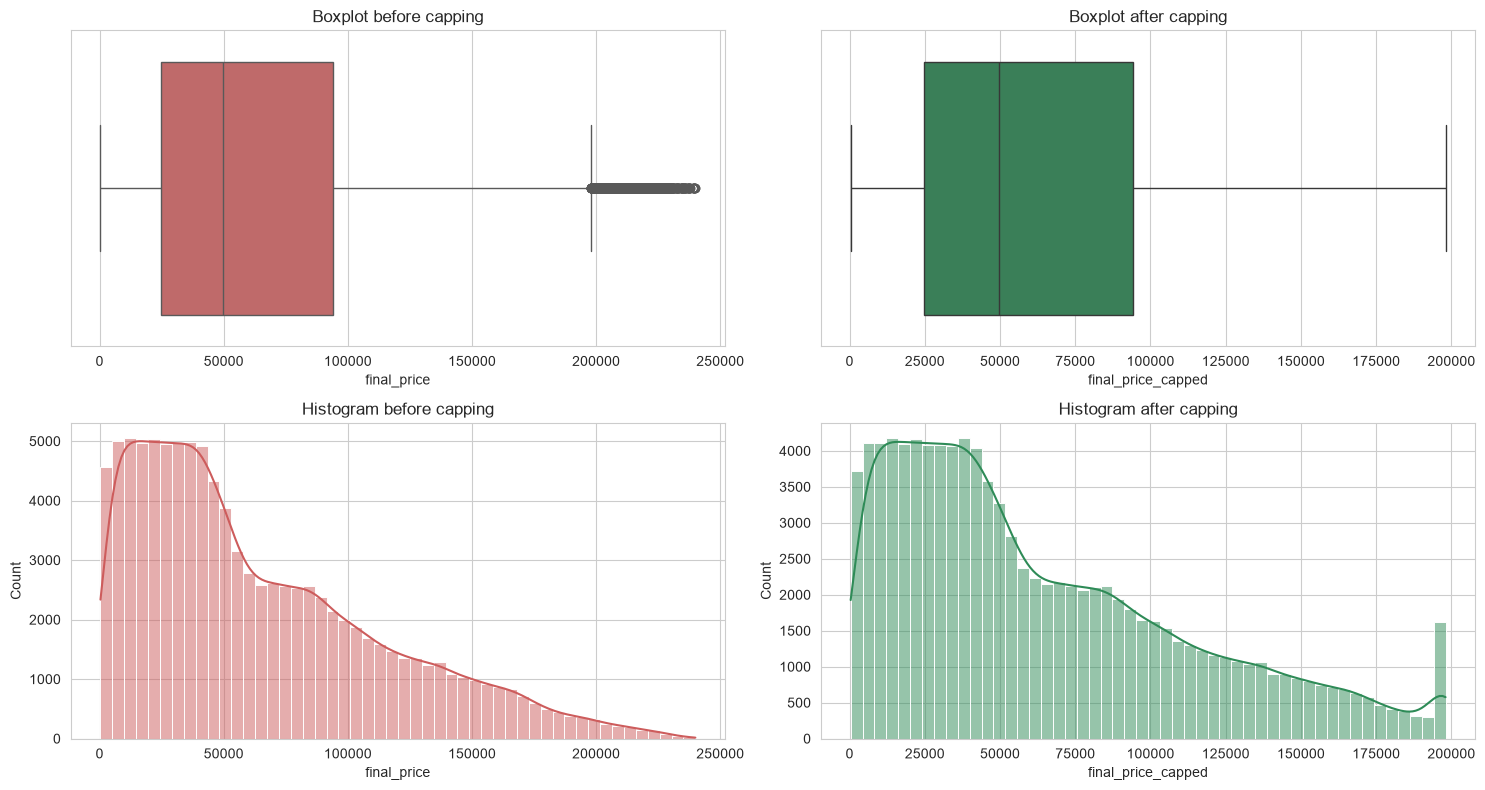

In [19]:
retail_data["final_price_capped"] = retail_data["final_price"].clip(lower=lower_limit, upper=upper_limit)

compare = pd.DataFrame({"before capping": retail_data["final_price"].describe(),
                        "after capping": retail_data["final_price_capped"].describe()})
compare.loc["skewness"] = [retail_data["final_price"].skew(), retail_data["final_price_capped"].skew()]
display(compare)

fig, axes = plt.subplots(2, 2, figsize=(15, 8))
sns.boxplot(x=retail_data["final_price"], color="indianred", ax=axes[0, 0])
axes[0, 0].set_title("Boxplot before capping")
sns.boxplot(x=retail_data["final_price_capped"], color="seagreen", ax=axes[0, 1])
axes[0, 1].set_title("Boxplot after capping")
sns.histplot(retail_data["final_price"], bins=50, kde=True, color="indianred", ax=axes[1, 0])
axes[1, 0].set_title("Histogram before capping")
sns.histplot(retail_data["final_price_capped"], bins=50, kde=True, color="seagreen", ax=axes[1, 1])
axes[1, 1].set_title("Histogram after capping")

plt.tight_layout()
plt.savefig("outputs/figures/08_capping.png", bbox_inches="tight")
plt.show()

**Interpretation:**
- 1,335 values were replaced by 198,058. The mean moved from 64,166 to 63,979 (about 0.3% lower), the median stayed at 49,752, the maximum dropped from 239,980 to 198,058 and the skewness from 0.93 to 0.88.
- After capping the boxplot shows no outlier points, and the histogram has a small bump at the cap value.

### 6.4 Effect of Capping and Saving the Data
Compare results before and after capping, then save the cleaned data as `Processed_dataset.csv`.

In [20]:
print("Average order value by customer segment")
display(retail_data.groupby("customer_segment")[["final_price", "final_price_capped"]].mean())

print("Correlation with final_price and with final_price_capped")
display(pd.DataFrame({
    "with final_price": retail_data[["product_price", "quantity", "discount_percentage", "age", "delivery_days"]].corrwith(retail_data["final_price"]),
    "with final_price_capped": retail_data[["product_price", "quantity", "discount_percentage", "age", "delivery_days"]].corrwith(retail_data["final_price_capped"]),
}))

retail_data.to_csv("data/Processed_dataset.csv", index=False)
print("Saved data/Processed_dataset.csv with", retail_data.shape[0], "rows and", retail_data.shape[1], "columns")

Average order value by customer segment


,final_price,final_price_capped
customer_segment,,
New,"63,766.75","63,584.86"
Premium,"64,430.45","64,243.79"
Regular,"64,303.15","64,111.04"


Correlation with final_price and with final_price_capped


,with final_price,with final_price_capped
product_price,0.73,0.73
quantity,0.58,0.58
discount_percentage,-0.14,-0.13
age,-0.00,-0.00
delivery_days,0.00,0.00


Saved data/Processed_dataset.csv with 100000 rows and 30 columns


**Interpretation:**
- Segment averages fall by about 0.3% and keep the same order (Premium, Regular, New). Correlations are unchanged: price 0.73, quantity 0.58, discount -0.14 (-0.13 after capping), age and delivery days 0.00.
- Capping does not change the results.
- `Processed_dataset.csv` is saved with 100,000 rows and 30 columns.

## 7. Bivariate Analysis: Numerical vs Numerical
Check how two numerical columns move together using scatter plots and Pearson correlation (+1 rise together, -1 move in opposite ways, 0 no linear relation).

### 7.1 Scatter Plots
A random sample of 6,000 orders is plotted so the dots stay readable.

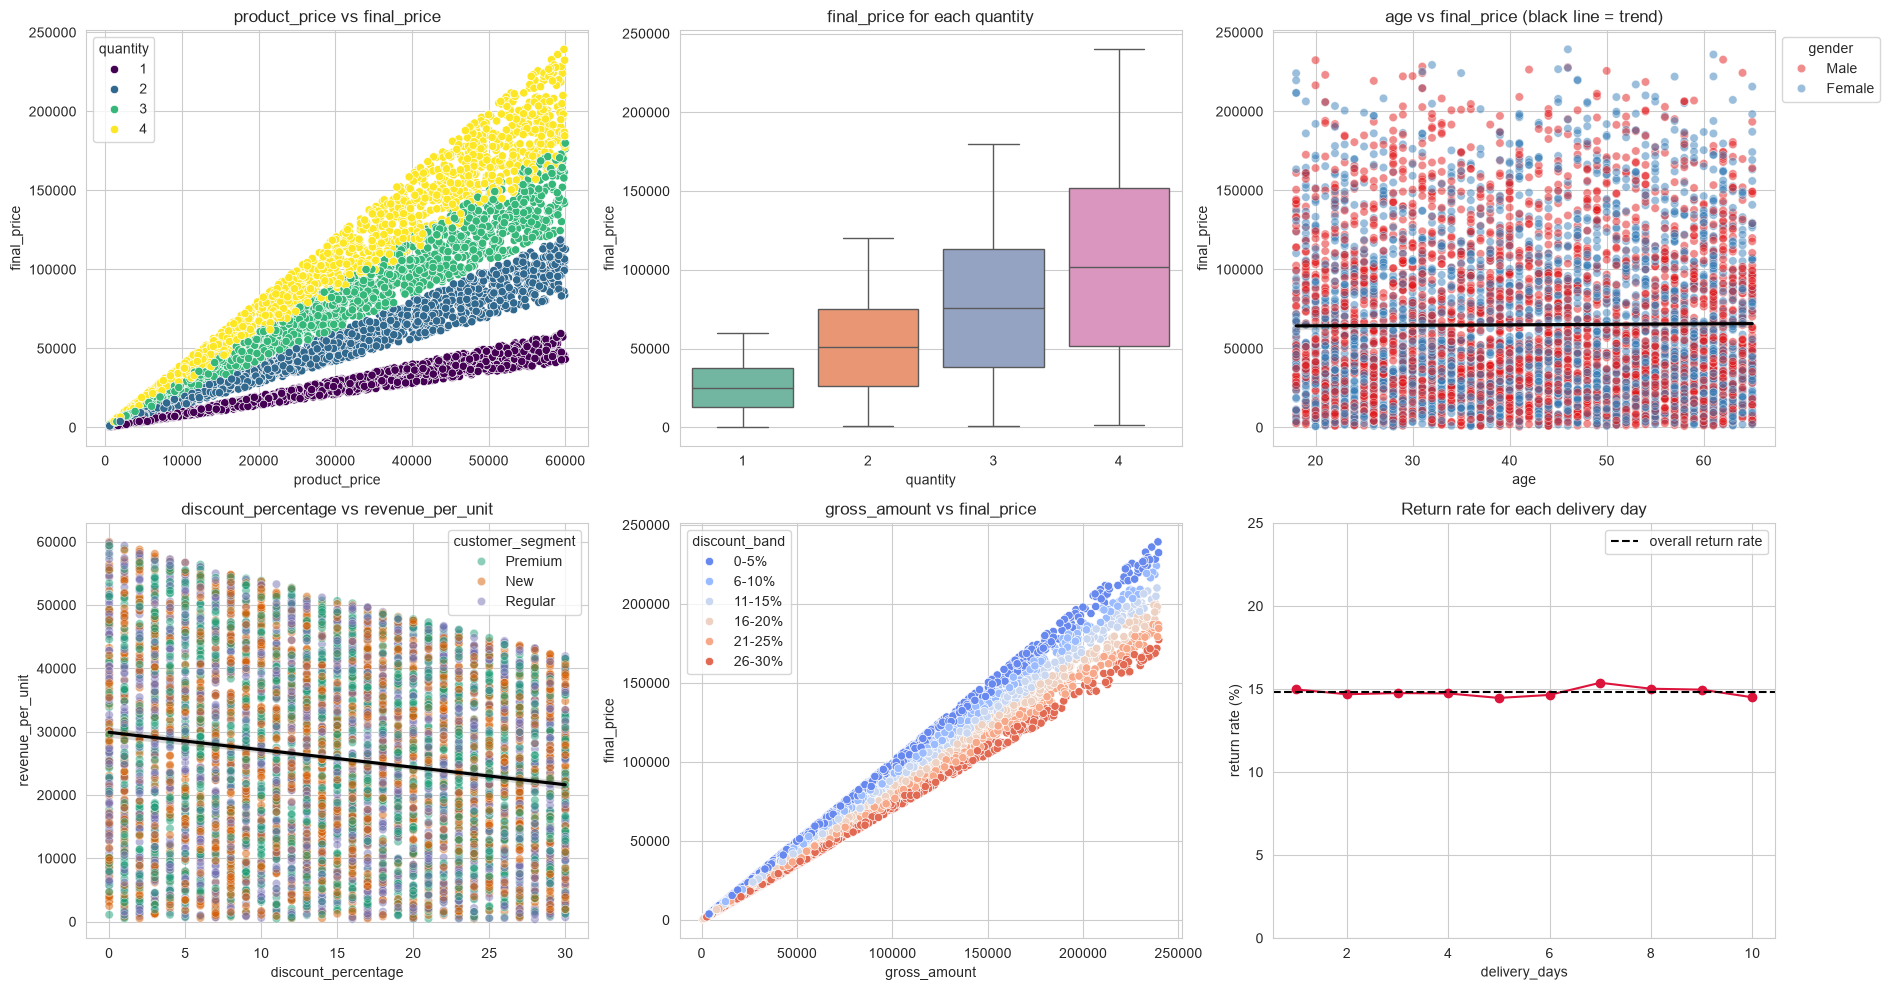

In [21]:
sample = retail_data.sample(6000, random_state=1)

fig, axes = plt.subplots(2, 3, figsize=(19, 10))

sns.scatterplot(data=sample, x="product_price", y="final_price", hue="quantity", palette="viridis", ax=axes[0, 0])
axes[0, 0].set_title("product_price vs final_price")

sns.boxplot(data=retail_data, x="quantity", y="final_price", hue="quantity", palette="Set2", legend=False, ax=axes[0, 1])
axes[0, 1].set_title("final_price for each quantity")

sns.scatterplot(data=sample, x="age", y="final_price", hue="gender", palette="Set1", alpha=0.5, ax=axes[0, 2])
sns.regplot(data=sample, x="age", y="final_price", scatter=False, color="black", ax=axes[0, 2])
axes[0, 2].set_title("age vs final_price (black line = trend)")
sns.move_legend(axes[0, 2], "upper left", bbox_to_anchor=(1, 1))

sns.scatterplot(data=sample, x="discount_percentage", y="revenue_per_unit", hue="customer_segment",
                palette="Dark2", alpha=0.5, ax=axes[1, 0])
sns.regplot(data=sample, x="discount_percentage", y="revenue_per_unit", scatter=False, color="black", ax=axes[1, 0])
axes[1, 0].set_title("discount_percentage vs revenue_per_unit")

sns.scatterplot(data=sample, x="gross_amount", y="final_price", hue="discount_band", palette="coolwarm", ax=axes[1, 1])
axes[1, 1].set_title("gross_amount vs final_price")

# return rate for each delivery day
return_by_days = retail_data.groupby("delivery_days")["is_return"].mean() * 100
axes[1, 2].plot(return_by_days.index, return_by_days.values, marker="o", color="crimson")
axes[1, 2].axhline(retail_data["is_return"].mean() * 100, color="black", linestyle="--", label="overall return rate")
axes[1, 2].set_ylim(0, 25)
axes[1, 2].set_xlabel("delivery_days")
axes[1, 2].set_ylabel("return rate (%)")
axes[1, 2].set_title("Return rate for each delivery day")
axes[1, 2].legend()

plt.tight_layout()
plt.savefig("outputs/figures/09_scatter_plots.png", bbox_inches="tight")
plt.show()

### 7.2 Correlation Values

In [22]:
corr_cols = ["age", "product_price", "quantity", "discount_percentage", "delivery_days",
             "final_price", "revenue_per_unit", "is_return"]
correlation = retail_data[corr_cols].corr()

correlation["final_price"].drop("final_price").sort_values(ascending=False).to_frame("correlation")

,correlation
revenue_per_unit,0.75
product_price,0.73
quantity,0.58
delivery_days,0.00
is_return,0.00
age,-0.00
discount_percentage,-0.14


**Interpretation:**
- `final_price` correlates 0.73 with `product_price`, 0.58 with `quantity` and -0.14 with `discount_percentage`. These follow from the formula (section 3.2) and do not describe customer behaviour.
- In the scatter plot `final_price` forms four bands, one for each quantity. The median order value rises from about 25,000 (1 unit) to about 100,000 (4 units).
- Age and delivery days have 0.00 correlation with spending.
- `is_return` has 0.00 correlation with every column, and the return rate stays near 14.8% for every delivery day.
- The input columns have about 0 correlation with each other. `revenue_per_unit` and `product_price` correlate 0.98 only because one is made from the other.
- The full correlation heatmap is in section 10.

## 8. Bivariate Analysis: Numerical vs Categorical
Compare spending and delivery time across groups: customer segment, category, payment method, shipping type, gender, age group and city.

### 8.1 Average and Median Order Value
The median is shown too, because big orders pull the mean up.

In [23]:
for col in ["customer_segment", "product_category", "payment_method", "shipping_type", "gender", "age_group", "city"]:
    print("Order value by", col)
    display(retail_data.groupby(col, observed=True)["final_price"].agg(["mean", "median", "count"]).sort_values("mean", ascending=False))

Order value by customer_segment


,mean,median,count
customer_segment,,,
Premium,"64,430.45","50,273.88",33151
Regular,"64,303.15","49,767.84",33361
New,"63,766.75","49,224.52",33488


Order value by product_category


,mean,median,count
product_category,,,
Home & Kitchen,"64,840.42","50,366.47",16848
Electronics,"64,329.67","50,195.79",16576
Grocery,"64,101.81","49,478.34",16592
Beauty,"64,030.55","49,621.32",16513
Fashion,"64,002.19","49,765.24",16613
Health,"63,686.69","49,294.98",16858


Order value by payment_method


,mean,median,count
payment_method,,,
Debit Card,"64,714.76","50,282.84",24560
UPI,"64,104.53","49,640.80",25139
Credit Card,"63,962.02","49,454.61",25307
Cash on Delivery,"63,894.03","49,628.15",24994


... (4 outputs left out)

Order value by age_group


,mean,median,count
age_group,,,
26-35,"64,600.49","49,893.48",20718
46-55,"64,411.14","50,064.14",20908
36-45,"64,004.92","49,647.76",20815
18-25,"63,903.33","49,132.48",16599
56-65,"63,858.66","49,990.13",20960


Order value by city


,mean,median,count
city,,,
Chennai,"65,107.98","50,638.80",9993
Mumbai,"64,787.77","50,402.88",10015
Jaipur,"64,481.22","49,277.34",9920
Kolkata,"64,286.89","49,872.00",9955
Ahmedabad,"64,102.31","49,816.20",10057
Hyderabad,"64,081.53","49,658.28",10150
Pune,"63,824.77","49,323.00",9937
Noida,"63,818.44","49,446.29",9964
Bangalore,"63,795.19","49,212.90",10047


### 8.2 Average Order Value
Bar charts. The dashed line is the overall average and the bars start at zero.

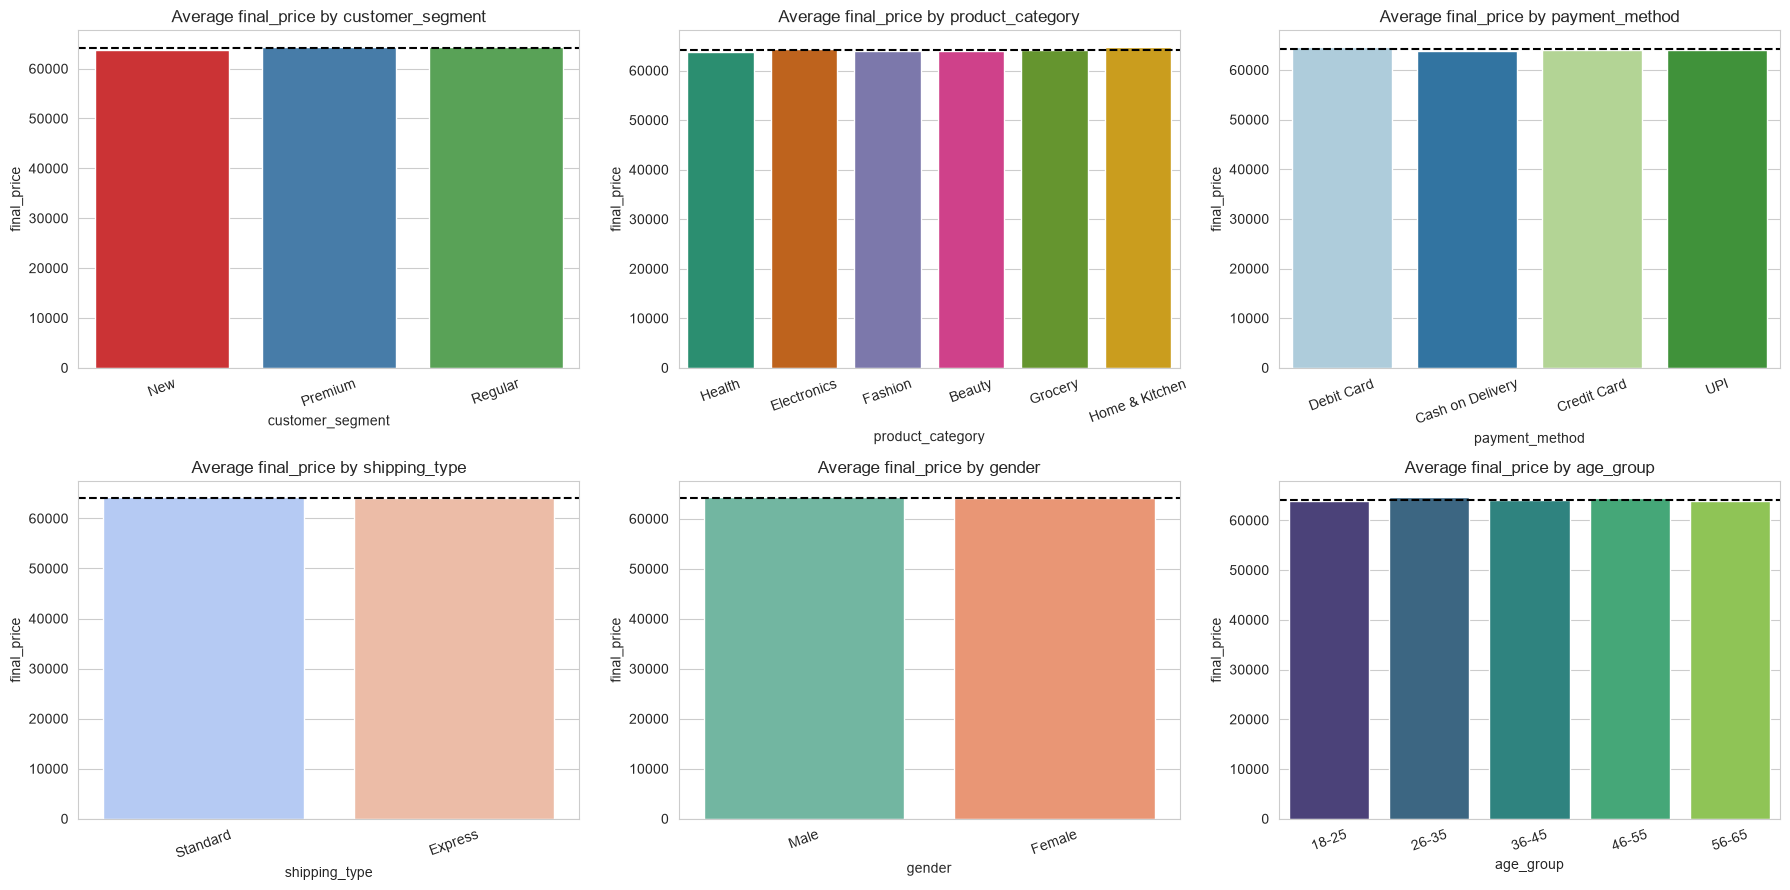

In [24]:
group_cols = ["customer_segment", "product_category", "payment_method", "shipping_type", "gender", "age_group"]
palettes = ["Set1", "Dark2", "Paired", "coolwarm", "Set2", "viridis"]

fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for ax, col, palette in zip(axes.flatten(), group_cols, palettes):
    sns.barplot(data=retail_data, x=col, y="final_price", hue=col, palette=palette,
                errorbar=None, dodge=False, legend=False, ax=ax)
    ax.axhline(retail_data["final_price"].mean(), color="black", linestyle="--")
    ax.set_title("Average final_price by " + col)
    ax.tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.savefig("outputs/figures/10_average_by_group.png", bbox_inches="tight")
plt.show()

### 8.3 Boxplots and Violin Plots

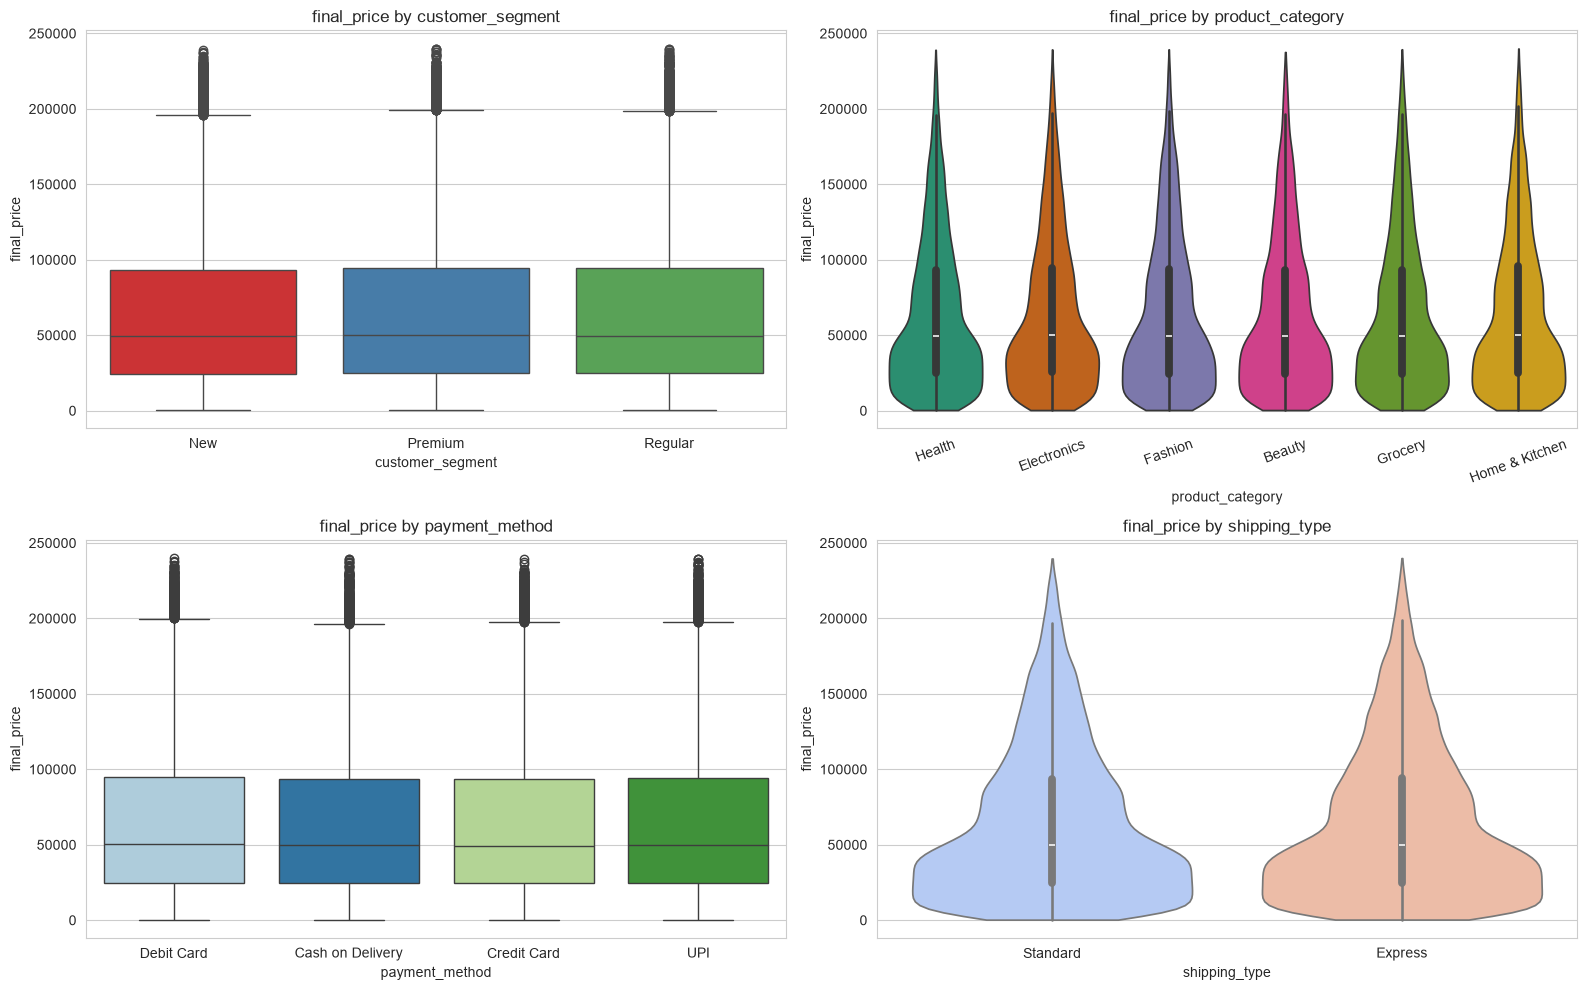

In [25]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

sns.boxplot(data=retail_data, x="customer_segment", y="final_price", hue="customer_segment", palette="Set1", legend=False, ax=axes[0, 0])
axes[0, 0].set_title("final_price by customer_segment")

sns.violinplot(data=retail_data, x="product_category", y="final_price", hue="product_category", palette="Dark2",
               legend=False, cut=0, ax=axes[0, 1])
axes[0, 1].set_title("final_price by product_category")
axes[0, 1].tick_params(axis="x", rotation=20)

sns.boxplot(data=retail_data, x="payment_method", y="final_price", hue="payment_method", palette="Paired", legend=False, ax=axes[1, 0])
axes[1, 0].set_title("final_price by payment_method")

sns.violinplot(data=retail_data, x="shipping_type", y="final_price", hue="shipping_type", palette="coolwarm",
               legend=False, cut=0, ax=axes[1, 1])
axes[1, 1].set_title("final_price by shipping_type")

plt.tight_layout()
plt.savefig("outputs/figures/11_boxplots_violins.png", bbox_inches="tight")
plt.show()

### 8.4 Shipping Type and Delivery Days
Check whether Express shipping delivers faster than Standard.

               mean  median  min  max
shipping_type                        
Express        5.50    5.00    1   10
Standard       5.51    6.00    1   10


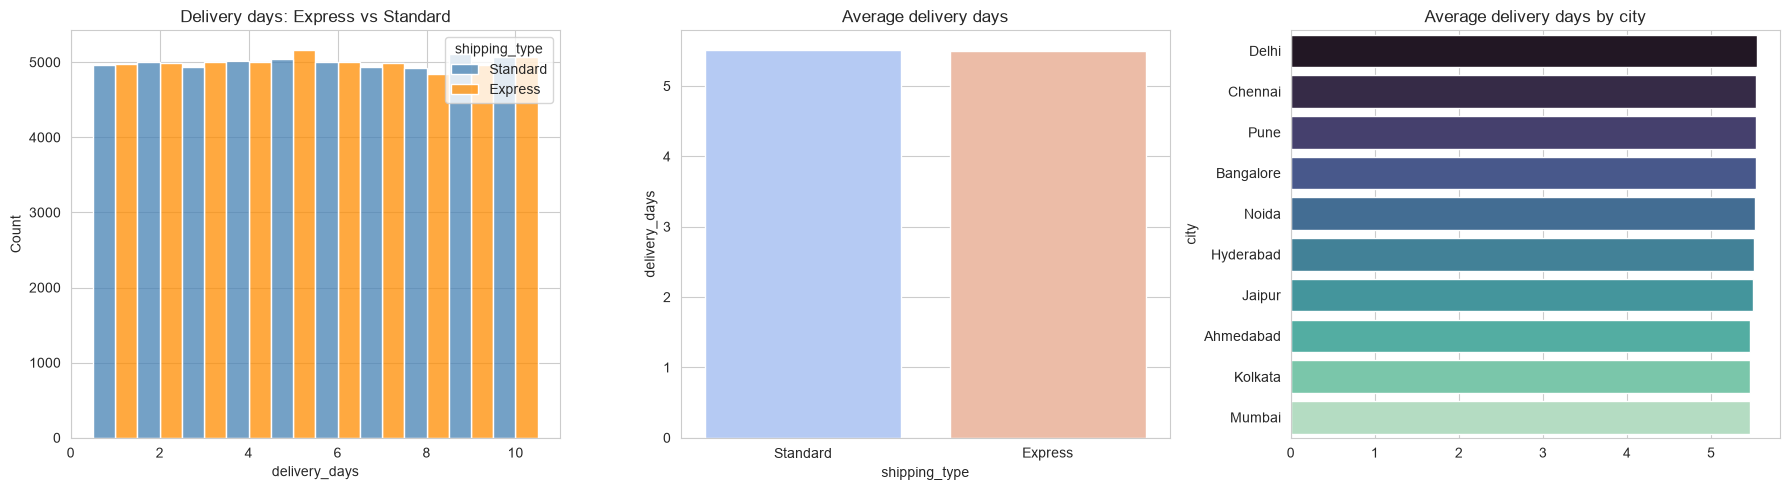

In [26]:
print(retail_data.groupby("shipping_type")["delivery_days"].agg(["mean", "median", "min", "max"]))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(data=retail_data, x="delivery_days", hue="shipping_type", multiple="dodge", discrete=True,
             palette=["steelblue", "darkorange"], ax=axes[0])
axes[0].set_title("Delivery days: Express vs Standard")

sns.barplot(data=retail_data, x="shipping_type", y="delivery_days", hue="shipping_type", palette="coolwarm",
            errorbar=None, legend=False, ax=axes[1])
axes[1].set_title("Average delivery days")

city_days = retail_data.groupby("city")["delivery_days"].mean().sort_values(ascending=False)
sns.barplot(x=city_days.values, y=city_days.index, hue=city_days.index, palette="mako", legend=False, ax=axes[2])
axes[2].set_title("Average delivery days by city")

plt.tight_layout()
plt.savefig("outputs/figures/12_delivery_days.png", bbox_inches="tight")
plt.show()

### 8.5 Statistical Test: ANOVA
ANOVA checks whether group averages differ by more than chance. A p-value above 0.05 means the difference is likely chance.

In [27]:
rows = []
for col in ["customer_segment", "product_category", "payment_method", "gender", "age_group", "city", "shipping_type"]:
    groups = [g["final_price"] for _, g in retail_data.groupby(col, observed=True)]
    f_value, p_value = stats.f_oneway(*groups)
    rows.append(["final_price", col, round(p_value, 3)])

# delivery days: Express vs Standard
groups = [g["delivery_days"] for _, g in retail_data.groupby("shipping_type")]
f_value, p_value = stats.f_oneway(*groups)
rows.append(["delivery_days", "shipping_type", round(p_value, 3)])

anova_table = pd.DataFrame(rows, columns=["compared column", "grouped by", "p-value"])
anova_table["real difference?"] = np.where(anova_table["p-value"] < 0.05, "Yes", "No")
anova_table

,compared column,grouped by,p-value,real difference?
0,final_price,customer_segment,0.19,No
1,final_price,product_category,0.40,No
2,final_price,payment_method,0.24,No
3,final_price,gender,0.56,No
4,final_price,age_group,0.47,No
5,final_price,city,0.38,No
6,final_price,shipping_type,0.87,No
7,delivery_days,shipping_type,0.37,No


**Interpretation:**
- Average order value is very close across groups: segment 63,767 (New) to 64,430 (Premium, about 1% higher), category 63,687 (Health) to 64,840 (Home & Kitchen), payment method 63,894 to 64,715 (Debit Card), age group 63,859 to 64,600 (26-35), city 63,371 (Delhi) to 65,108 (Chennai), gender 64,257 and 64,074, shipping type 64,140 and 64,191.
- Medians are also close (about 49,000 to 50,600) and lower than the means in every group because of the long right tail.
- Express and Standard average 5.50 and 5.51 delivery days, so Express is not faster here. Delivery time is also similar across cities (5.46 to 5.54 days).
- All ANOVA p-values are above 0.05 (0.19 to 0.87 for order value, 0.37 for delivery days by shipping type), so these differences are likely chance.
- Order value depends on price, quantity and discount, not on customer segment, gender, age, city or payment method.

## 9. Bivariate Analysis: Categorical vs Categorical
Check whether the return rate changes across groups and whether returns are related to any categorical column.

### 9.1 Return Rate by Group

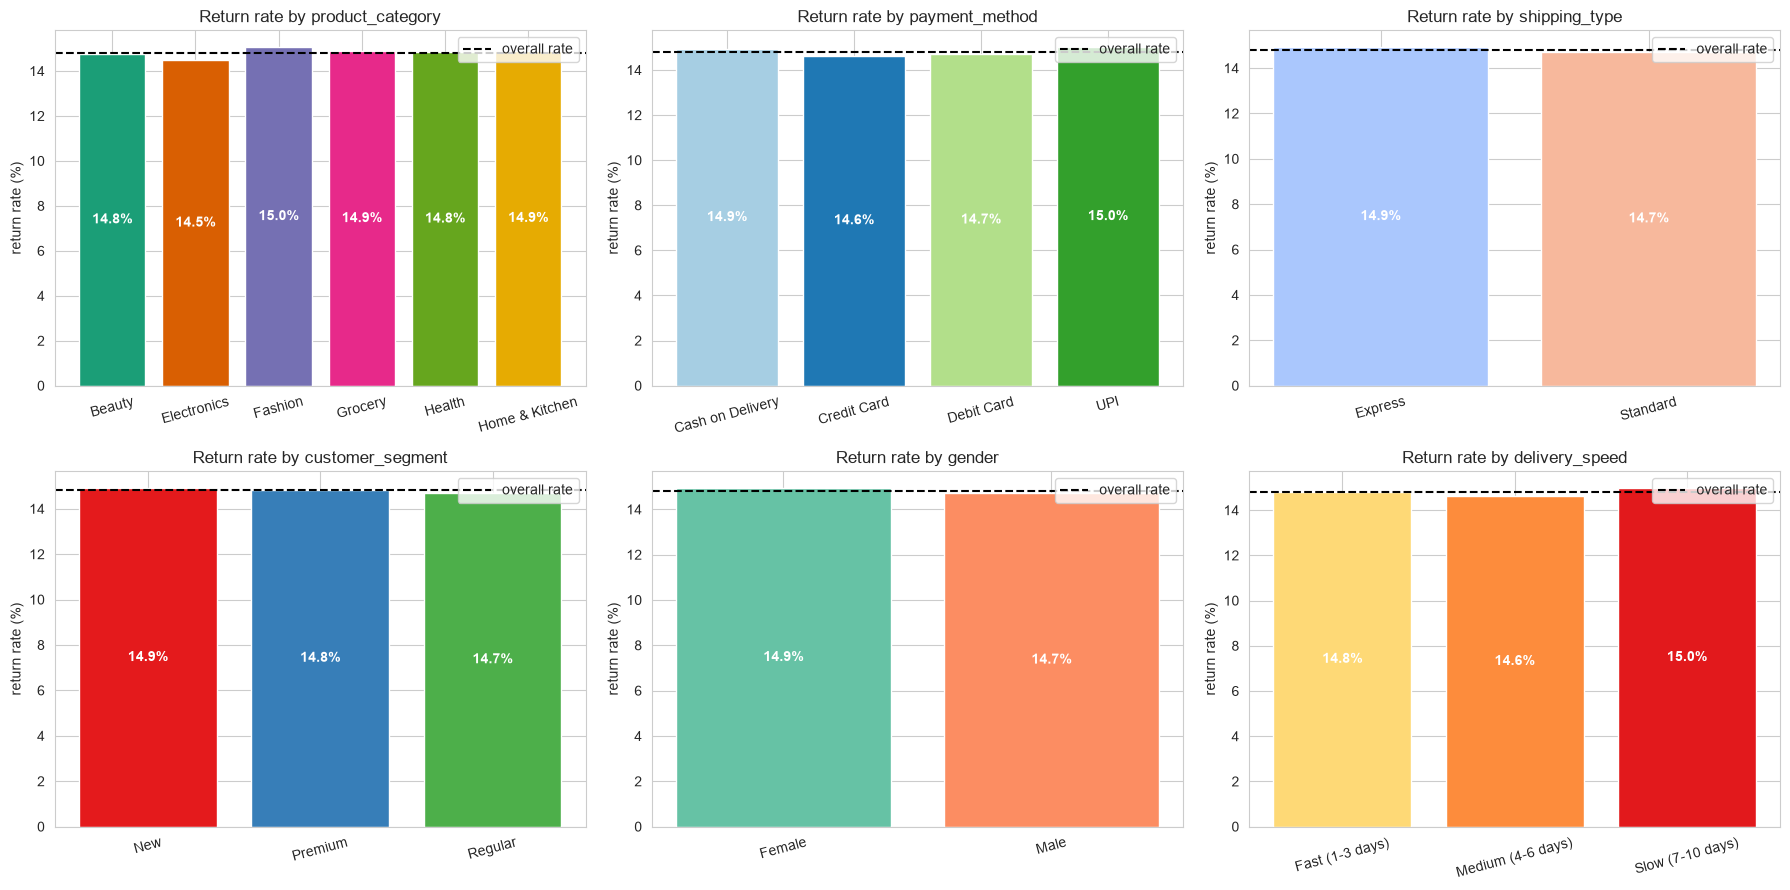

In [28]:
cols = ["product_category", "payment_method", "shipping_type", "customer_segment", "gender", "delivery_speed"]
palettes = ["Dark2", "Paired", "coolwarm", "Set1", "Set2", "YlOrRd"]
overall_rate = retail_data["is_return"].mean() * 100

fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for ax, col, palette in zip(axes.flatten(), cols, palettes):
    rate = retail_data.groupby(col, observed=True)["is_return"].mean() * 100
    bars = ax.bar(rate.index.astype(str), rate.values, color=sns.color_palette(palette, len(rate)))
    ax.bar_label(bars, fmt="%.1f%%", label_type="center", color="white", fontweight="bold")
    ax.axhline(overall_rate, color="black", linestyle="--", label="overall rate")
    ax.set_title("Return rate by " + col)
    ax.set_ylabel("return rate (%)")
    ax.tick_params(axis="x", rotation=15)
    ax.legend(loc="upper right")

plt.tight_layout()
plt.savefig("outputs/figures/13_return_rate_by_group.png", bbox_inches="tight")
plt.show()

### 9.2 Returned and Not Returned Orders

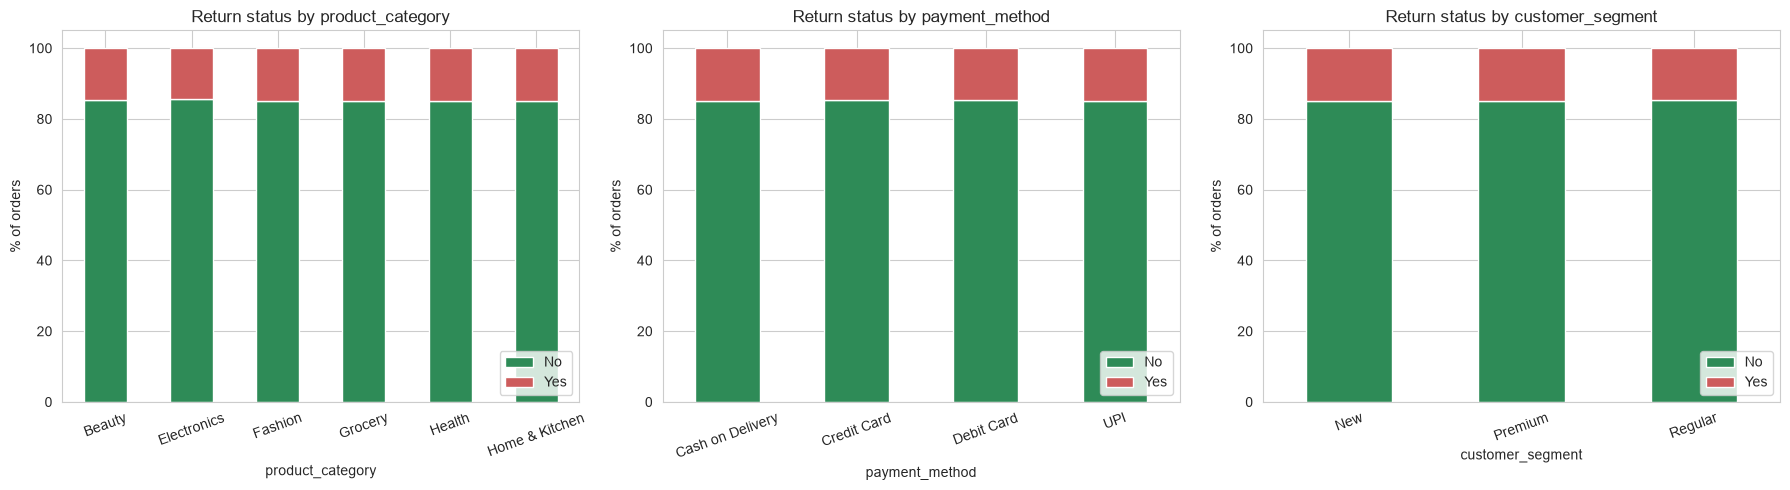

In [29]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, col in zip(axes, ["product_category", "payment_method", "customer_segment"]):
    share = pd.crosstab(retail_data[col], retail_data["return_status"], normalize="index") * 100
    share.plot(kind="bar", stacked=True, color=["seagreen", "indianred"], ax=ax, rot=20)
    ax.set_title("Return status by " + col)
    ax.set_ylabel("% of orders")
    ax.legend(loc="lower right")

plt.tight_layout()
plt.savefig("outputs/figures/14_stacked_bars.png", bbox_inches="tight")
plt.show()

### 9.3 Statistical Test: Chi-square
Chi-square checks whether two categorical columns are related. A p-value above 0.05 means no clear relation. Each column is tested against `return_status`.

In [30]:
rows = []
for col in ["product_category", "product_subcategory", "payment_method", "shipping_type", "customer_segment",
            "gender", "city", "age_group", "discount_band", "delivery_speed"]:
    table = pd.crosstab(retail_data[col], retail_data["return_status"])
    chi2, p_value, dof, expected = stats.chi2_contingency(table)
    cramers_v = np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1)))
    rows.append([col, round(p_value, 3), round(cramers_v, 4)])

chi_table = pd.DataFrame(rows, columns=["column tested against return_status", "p-value", "Cramér's V"])
chi_table["related to returns?"] = np.where(chi_table["p-value"] < 0.05, "Yes", "No")
chi_table

,column tested against return_status,p-value,Cramér's V,related to returns?
0,product_category,0.79,0.00,No
1,product_subcategory,0.24,0.02,No
2,payment_method,0.61,0.00,No
3,shipping_type,0.38,0.00,No
4,customer_segment,0.77,0.00,No
5,gender,0.32,0.00,No
6,city,0.94,0.01,No
7,age_group,0.81,0.00,No
8,discount_band,0.47,0.01,No
9,delivery_speed,0.43,0.00,No


**Interpretation:**
- The overall return rate is 14.81% and every group is close to it: category 14.5% (Electronics) to 15.1% (Fashion), payment method 14.6% to 15.0%, segment 14.7% to 14.9%, gender 14.7% and 14.9%, delivery speed 14.6% to 15.0%.
- Electronics has the lowest return rate among the categories, and Standard shipping (14.7%) is not higher than Express (14.9%).
- The stacked bars show about 85% kept and 15% returned in every group.
- All chi-square p-values are above 0.05 (0.24 to 0.94). Returns are not related to category, subcategory, payment method, shipping type, segment, gender, city, age group, discount band or delivery speed.
- Subcategories range from 13.75% (Cookware) to 15.91% (Blender), but with only 4,000 to 5,700 orders each this is within chance (p = 0.24).
Cramér's V is below 0.02 for every column (0.002 to 0.016), so the link with returns is negligible.

## 10. Multivariate Analysis
Look at three or more columns together using pivot tables, heatmaps, a pairplot and a facet grid.

### 10.1 Product Category, Discount and Average Final Price

discount_band,0-5%,6-10%,11-15%,16-20%,21-25%,26-30%
product_category,,,,,,
Beauty,"72,928.00","70,167.00","65,128.00","61,099.00","57,874.00","55,350.00"
Electronics,"73,734.00","70,157.00","64,795.00","62,932.00","58,105.00","54,095.00"
Fashion,"73,242.00","68,452.00","65,940.00","61,594.00","58,831.00","53,935.00"
Grocery,"74,227.00","70,397.00","64,900.00","63,500.00","57,205.00","52,726.00"
Health,"73,364.00","68,190.00","65,049.00","62,256.00","56,622.00","54,707.00"
Home & Kitchen,"74,502.00","71,391.00","66,690.00","62,319.00","58,328.00","54,036.00"


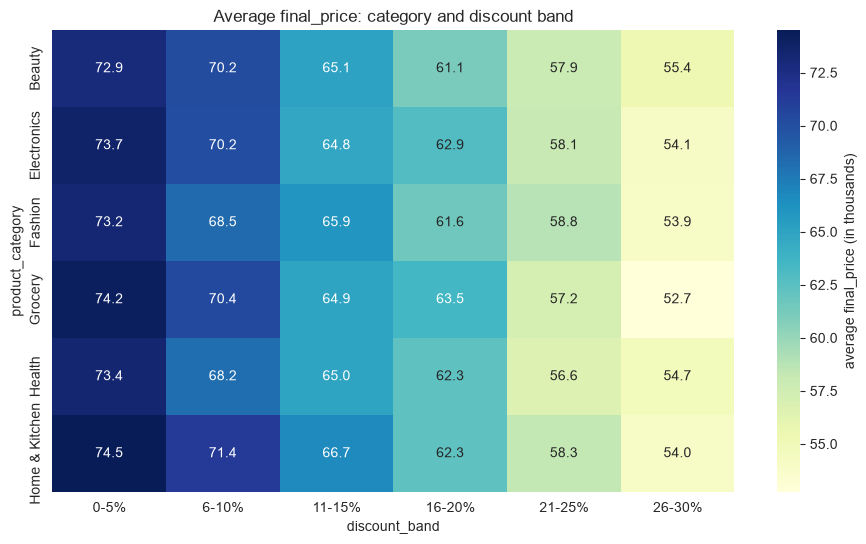

In [31]:
pivot_cd = retail_data.pivot_table(values="final_price", index="product_category", columns="discount_band",
                                   aggfunc="mean", observed=True)
display(pivot_cd.round(0))

plt.figure(figsize=(11, 6))
sns.heatmap(pivot_cd / 1000, annot=True, fmt=".1f", cmap="YlGnBu", cbar_kws={"label": "average final_price (in thousands)"})
plt.title("Average final_price: category and discount band")
plt.savefig("outputs/figures/15_category_discount.png", bbox_inches="tight")
plt.show()

### 10.2 Customer Segment, Age Group and Average Spending

age_group,18-25,26-35,36-45,46-55,56-65
customer_segment,,,,,
New,"63,588.00","64,165.00","63,879.00","63,513.00","63,659.00"
Premium,"64,026.00","65,282.00","64,034.00","65,432.00","63,295.00"
Regular,"64,097.00","64,359.00","64,104.00","64,295.00","64,616.00"


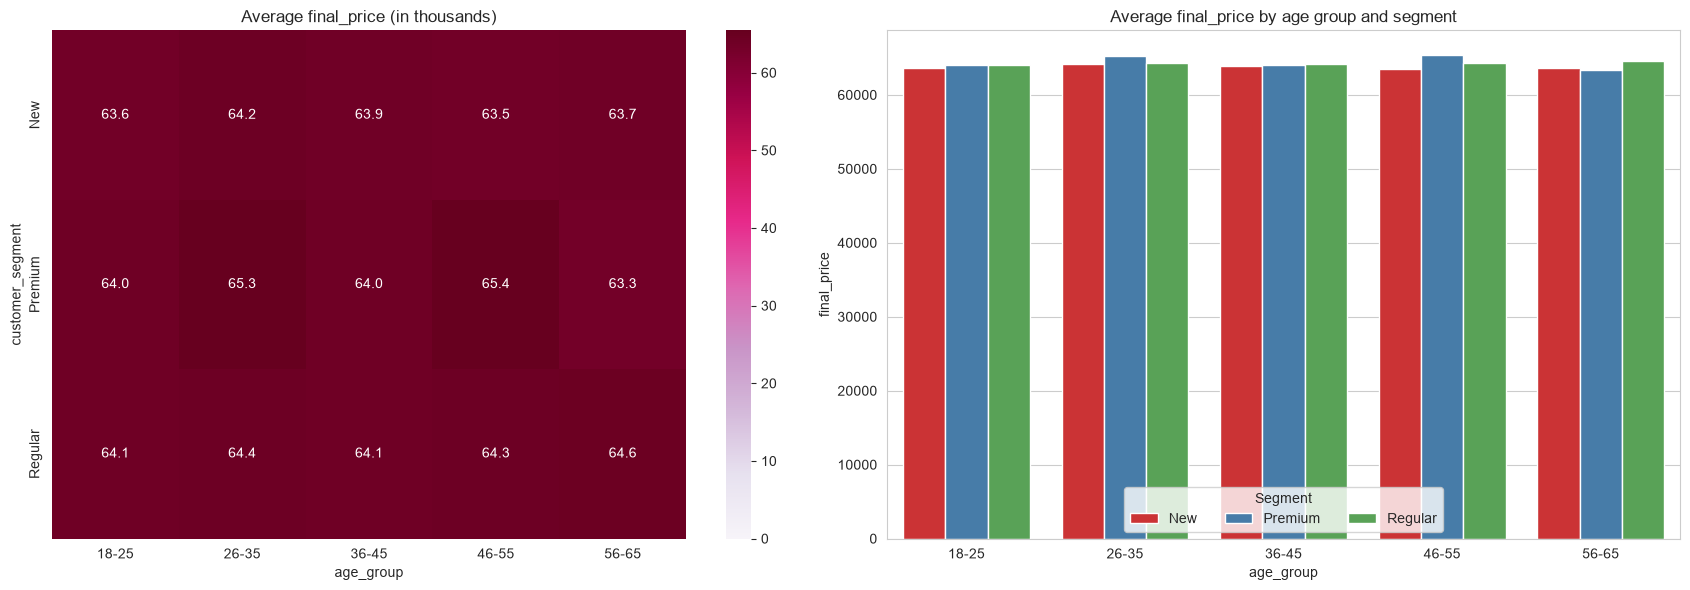

In [32]:
pivot_sa = retail_data.pivot_table(values="final_price", index="customer_segment", columns="age_group",
                                   aggfunc="mean", observed=True)
display(pivot_sa.round(0))

fig, axes = plt.subplots(1, 2, figsize=(17, 6))
sns.heatmap(pivot_sa / 1000, annot=True, fmt=".1f", cmap="PuRd", vmin=0, ax=axes[0])
axes[0].set_title("Average final_price (in thousands)")
sns.barplot(data=retail_data, x="age_group", y="final_price", hue="customer_segment", palette="Set1", errorbar=None, ax=axes[1])
axes[1].set_title("Average final_price by age group and segment")
axes[1].legend(title="Segment", ncol=3, loc="lower center")

plt.tight_layout()
plt.savefig("outputs/figures/16_segment_age.png", bbox_inches="tight")
plt.show()

### 10.3 Shipping Type, Delivery Days and Return Rate

delivery_days,1,2,3,4,5,6,7,8,9,10
shipping_type,,,,,,,,,,
Express,14.70,14.60,15.20,14.60,15.10,14.40,16.20,14.80,14.80,14.80
Standard,15.20,14.80,14.30,14.90,13.80,14.90,14.50,15.30,15.20,14.20


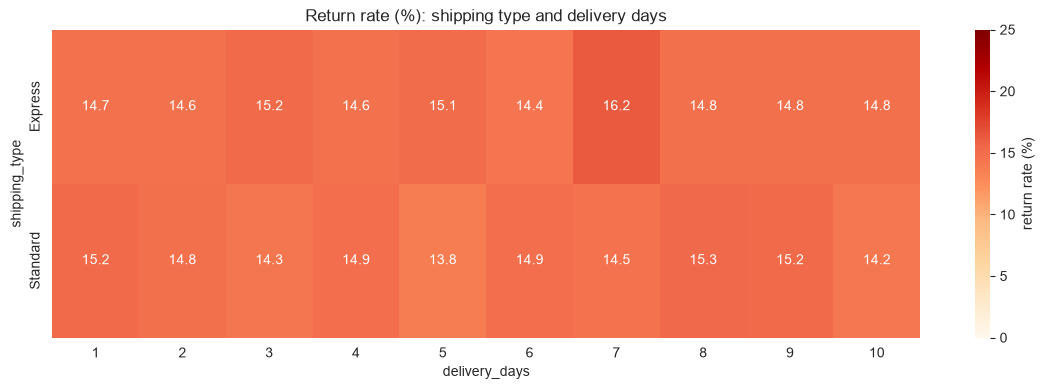

In [33]:
pivot_sd = retail_data.pivot_table(values="is_return", index="shipping_type", columns="delivery_days", aggfunc="mean") * 100
display(pivot_sd.round(1))

plt.figure(figsize=(14, 4))
sns.heatmap(pivot_sd, annot=True, fmt=".1f", cmap="OrRd", vmin=0, vmax=25, cbar_kws={"label": "return rate (%)"})
plt.title("Return rate (%): shipping type and delivery days")
plt.savefig("outputs/figures/17_shipping_delivery_return.png", bbox_inches="tight")
plt.show()

### 10.4 City, Category and Revenue

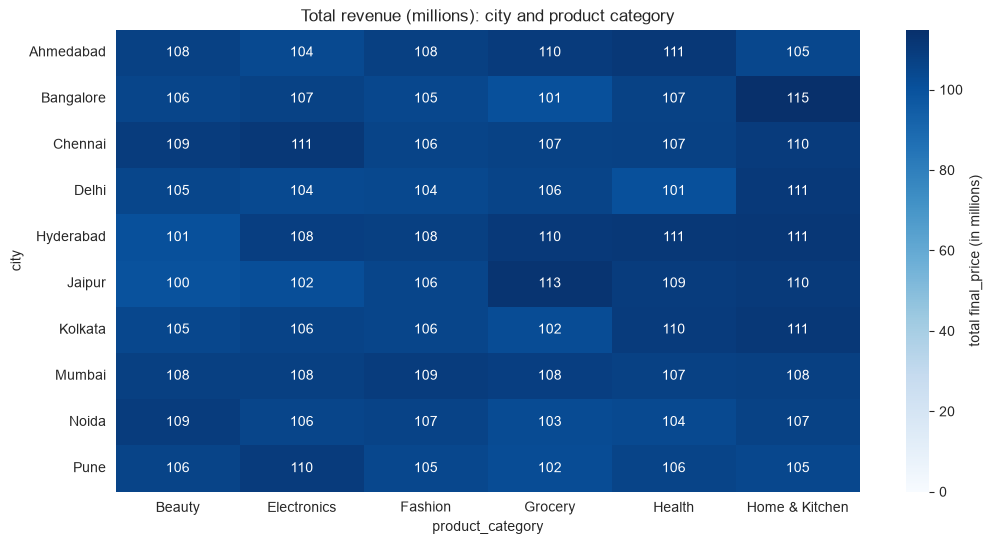

In [34]:
pivot_city = retail_data.pivot_table(values="final_price", index="city", columns="product_category", aggfunc="sum") / 1000000

plt.figure(figsize=(12, 6))
sns.heatmap(pivot_city, annot=True, fmt=".0f", cmap="Blues", vmin=0, cbar_kws={"label": "total final_price (in millions)"})
plt.title("Total revenue (millions): city and product category")
plt.savefig("outputs/figures/18_city_category_revenue.png", bbox_inches="tight")
plt.show()

**Interpretation:**
- **Category, discount and price:** in every category the average final price falls as the discount rises, from about 73,000 to 74,500 in the 0-5% band to about 52,700 to 55,400 in the 26-30% band (around 26% lower). The highest value is Home & Kitchen with 0-5% discount (74,502), while Electronics with 11-15% discount is 64,795. Moderate discounts do not give the highest value.
- **Segment, age and spending:** all averages are between 63,295 (Premium, 56-65) and 65,432 (Premium, 46-55), within about 2% of the overall average. No segment leads in every age group.
- **Shipping, delivery days and returns:** the return rate is between 13.8% (Standard, 5 days) and 16.2% (Express, 7 days) and does not rise with delivery days.
- **City and category:** every cell of the revenue heatmap is about 100 to 115 million, so no city is strong in only one category.

### 10.5 Return Rate Heatmaps
Return rate by category and shipping type, and by payment method and customer segment.

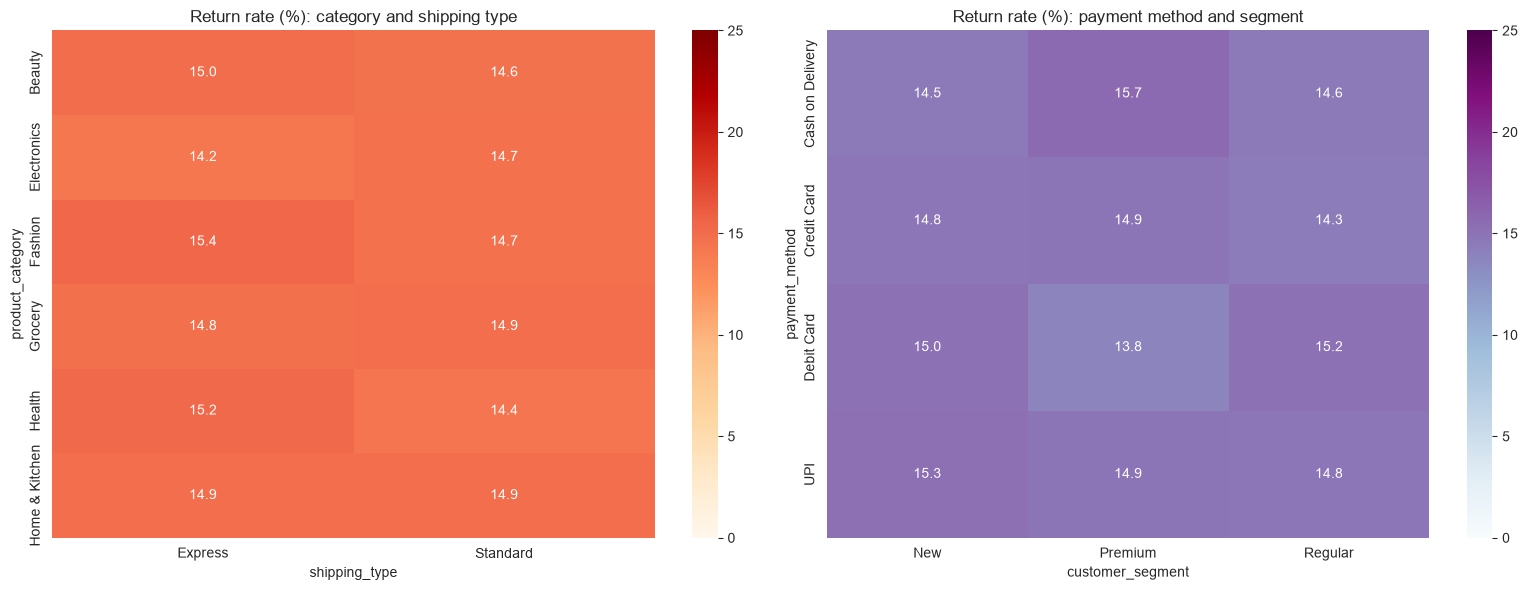

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

pivot_1 = retail_data.pivot_table(values="is_return", index="product_category", columns="shipping_type", aggfunc="mean") * 100
sns.heatmap(pivot_1, annot=True, fmt=".1f", cmap="OrRd", vmin=0, vmax=25, ax=axes[0])
axes[0].set_title("Return rate (%): category and shipping type")

pivot_2 = retail_data.pivot_table(values="is_return", index="payment_method", columns="customer_segment", aggfunc="mean") * 100
sns.heatmap(pivot_2, annot=True, fmt=".1f", cmap="BuPu", vmin=0, vmax=25, ax=axes[1])
axes[1].set_title("Return rate (%): payment method and segment")

plt.tight_layout()
plt.savefig("outputs/figures/19_return_rate_heatmaps.png", bbox_inches="tight")
plt.show()

### 10.6 Correlation Heatmap
Correlation between all numerical columns, using the values from section 7.2.

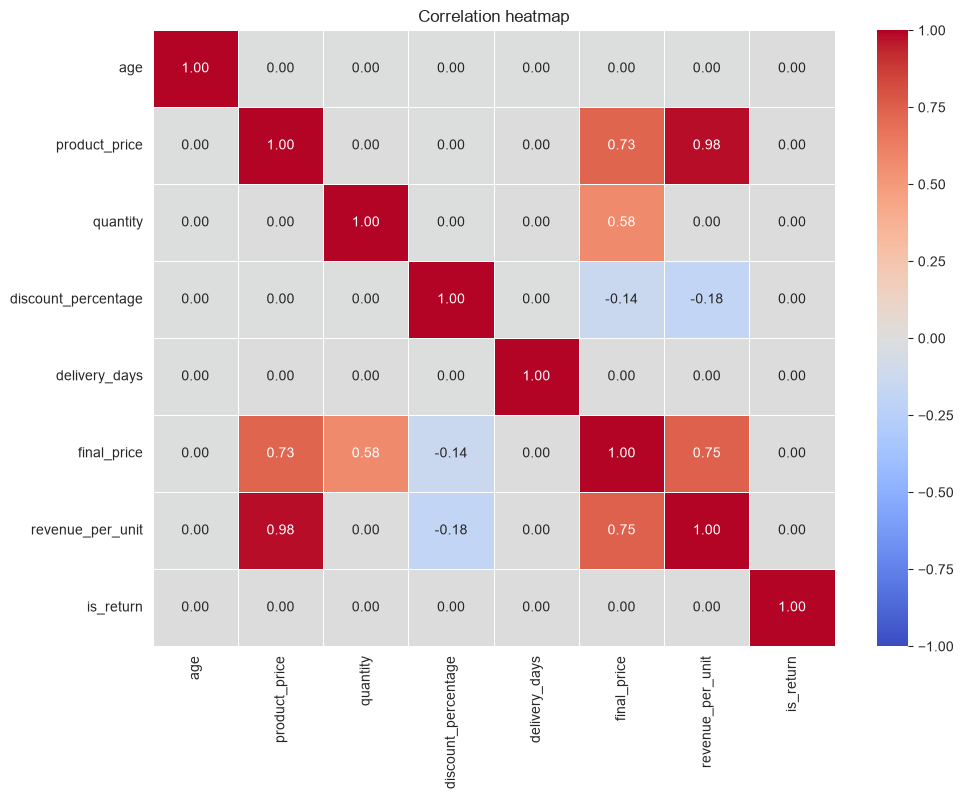

In [36]:
plt.figure(figsize=(11, 8))
sns.heatmap(correlation, annot=correlation.round(2) + 0.0, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, linewidths=0.5)
plt.title("Correlation heatmap")
plt.savefig("outputs/figures/20_correlation_heatmap.png", bbox_inches="tight")
plt.show()

**Interpretation:**
- In the return rate heatmaps every cell is between about 14% and 16% and the colours look the same on the 0 to 25 scale.
- In the correlation heatmap, notable values appear only between `final_price` or `revenue_per_unit` and the columns they are made from (price, quantity, discount), which follows from the formulas. All other pairs are about 0.

### 10.7 Pairplot and Facet Grid
The pairplot shows every numerical column against every other one, coloured by customer segment (2,500 orders). The facet grid makes one chart for each customer segment.

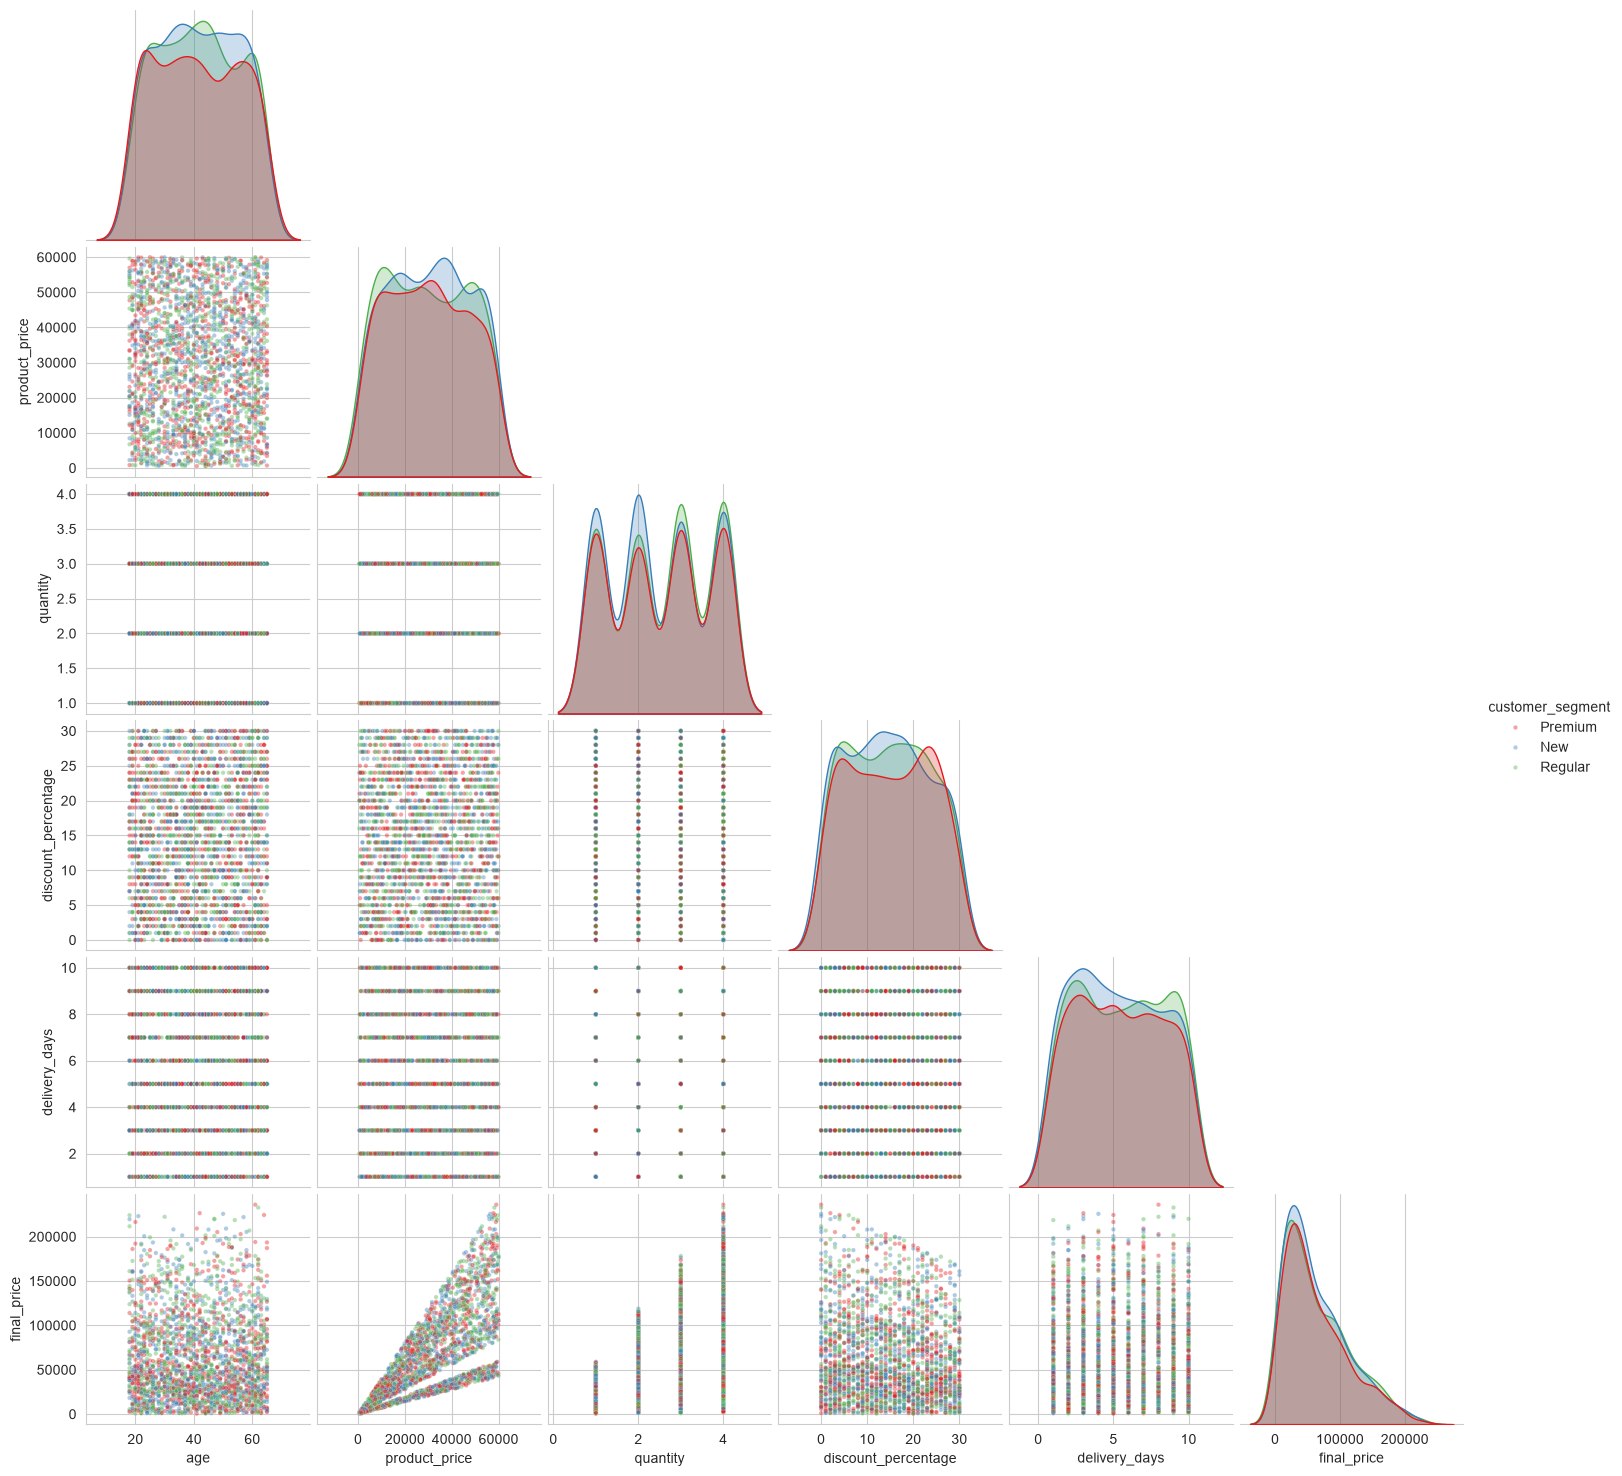

In [37]:
pairplot_columns = ["age", "product_price", "quantity", "discount_percentage", "delivery_days", "final_price"]
sns.pairplot(retail_data.sample(2500, random_state=1), vars=pairplot_columns, hue="customer_segment",
             palette="Set1", corner=True, plot_kws={"alpha": 0.4, "s": 10})
plt.savefig("outputs/figures/21_pairplot.png", bbox_inches="tight")
plt.show()

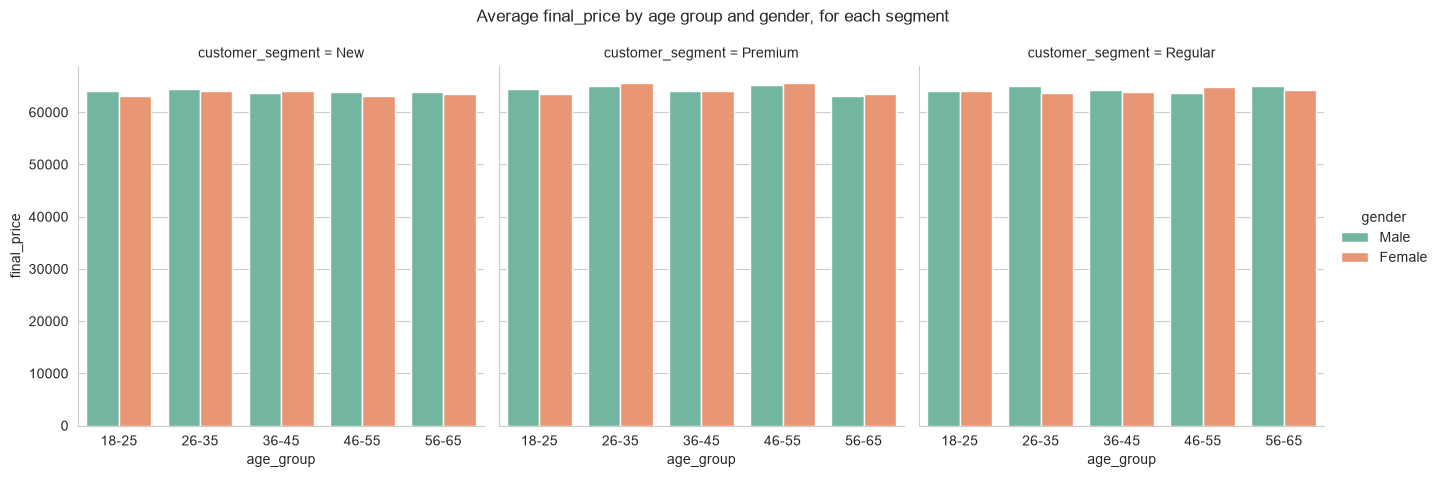

In [38]:
grid = sns.catplot(data=retail_data, x="age_group", y="final_price", hue="gender", col="customer_segment",
                   kind="bar", palette="Set2", errorbar=None, height=4.5)
grid.figure.suptitle("Average final_price by age group and gender, for each segment", y=1.05)
plt.savefig("outputs/figures/22_facet_grid.png", bbox_inches="tight")
plt.show()

### 10.8 Relation Between Input Columns
Check whether the input columns are related to each other (multicollinearity). `final_price` is left out because it is calculated from them.

In [39]:
input_columns = ["age", "product_price", "quantity", "discount_percentage", "delivery_days"]
retail_data[input_columns].corr().round(3)

,age,product_price,quantity,discount_percentage,delivery_days
age,1.00,-0.00,-0.00,-0.00,-0.00
product_price,-0.00,1.00,0.00,-0.00,0.00
quantity,-0.00,0.00,1.00,-0.00,0.00
discount_percentage,-0.00,-0.00,-0.00,1.00,-0.00
delivery_days,-0.00,0.00,0.00,-0.00,1.00


**Interpretation:**
- In the pairplot, age, price, quantity, discount and delivery days against each other show evenly filled dots with no pattern. Only the `final_price` row shows a pattern (up with price and quantity, down with discount), which is the formula. The three segment colours overlap in every plot.
- In the facet grid all age groups and both genders have bars at about the same height (around 64,000) in all three segments.
- Correlations between the input columns are all 0.00, so there is no multicollinearity problem.

## 11. Additional Analysis
Explore further trends: sales over time, cities and states, products and the effect of discounts.

### 11.1 Sales Over Time

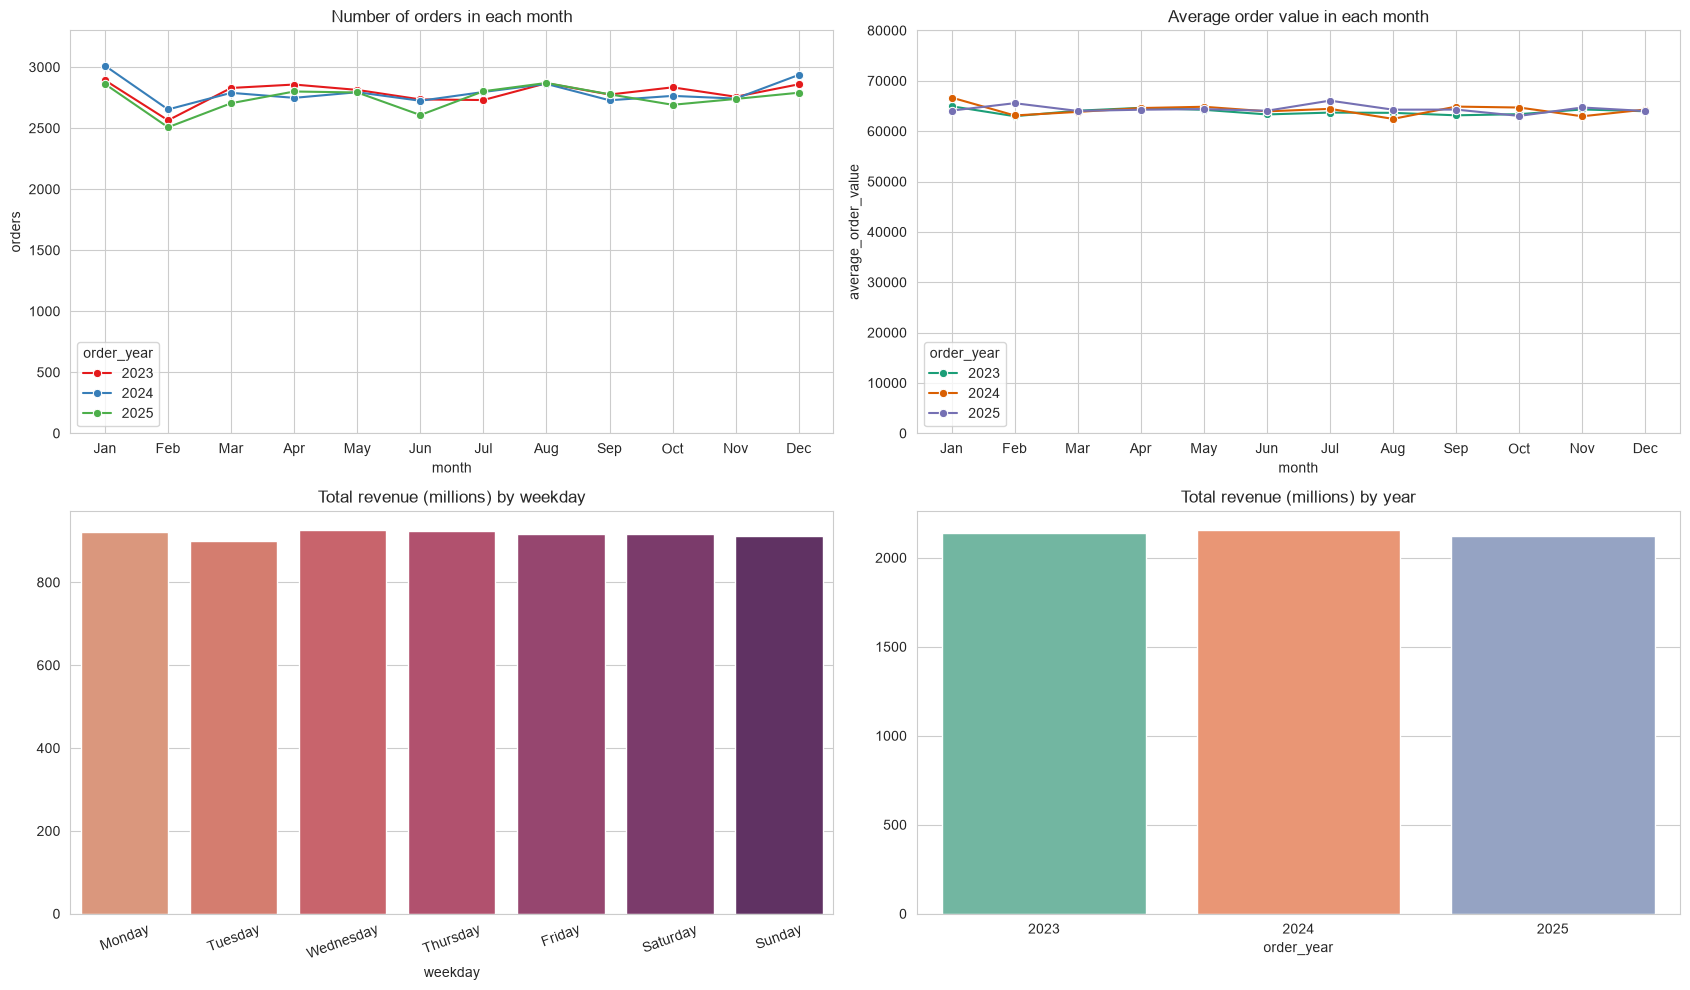

,orders,revenue,average_order_value,return_rate
order_year,,,,
2023,33513,"2,140,485,042.87","63,870.29",14.46
2024,33547,"2,155,130,180.21","64,242.11",15.00
2025,32940,"2,120,957,115.16","64,388.50",14.98


In [40]:
# orders and average order value for every month of every year
monthly = retail_data.groupby(["order_year", "order_month"]).agg(orders=("order_id", "count"),
                                                                 average_order_value=("final_price", "mean")).reset_index()

month_names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

fig, axes = plt.subplots(2, 2, figsize=(17, 10))

sns.lineplot(data=monthly, x="order_month", y="orders", hue="order_year", palette="Set1", marker="o", ax=axes[0, 0])
axes[0, 0].set_title("Number of orders in each month")

sns.lineplot(data=monthly, x="order_month", y="average_order_value", hue="order_year", palette="Dark2", marker="o", ax=axes[0, 1])
axes[0, 1].set_title("Average order value in each month")

weekday_revenue = retail_data.groupby("weekday")["final_price"].sum().reindex(weekday_order) / 1000000
sns.barplot(x=weekday_revenue.index, y=weekday_revenue.values, hue=weekday_revenue.index, palette="flare", legend=False, ax=axes[1, 0])
axes[1, 0].set_title("Total revenue (millions) by weekday")
axes[1, 0].tick_params(axis="x", rotation=20)

year_revenue = retail_data.groupby("order_year")["final_price"].sum() / 1000000
sns.barplot(x=year_revenue.index, y=year_revenue.values, hue=year_revenue.index, palette="Set2", legend=False, ax=axes[1, 1])
axes[1, 1].set_title("Total revenue (millions) by year")

for ax in (axes[0, 0], axes[0, 1]):
    ax.set_xticks(range(1, 13))
    ax.set_xticklabels(month_names)
    ax.set_xlabel("month")
axes[0, 0].set_ylim(0, 3300)
axes[0, 1].set_ylim(0, 80000)

plt.tight_layout()
plt.savefig("outputs/figures/23_time_analysis.png", bbox_inches="tight")
plt.show()

yearly = retail_data.groupby("order_year").agg(orders=("order_id", "count"), revenue=("final_price", "sum"),
                                               average_order_value=("final_price", "mean"), return_rate=("is_return", "mean"))
yearly["return_rate"] = yearly["return_rate"] * 100
yearly

**Interpretation:**
- The three years are similar. Orders were 33,513 (2023), 33,547 (2024) and 32,940 (2025), revenue 2,140, 2,155 and 2,121 million, average order value 63,870, 64,242 and 64,389, and return rate 14.5%, 15.0% and 15.0%. Revenue in 2025 is about 1.6% below 2024.
- Monthly orders are about 2,500 to 3,000 (February is lower because it has fewer days) and the average order value stays between about 62,000 and 67,000. There is no clear growth, decline or seasonal pattern.
- Revenue on each weekday is about 900 to 925 million, so no day stands out.

### 11.2 Cities and States

,orders,revenue,average_order_value,return_rate
city,,,,
Chennai,9993,650.62,"65,107.98",15.12
Hyderabad,10150,650.43,"64,081.53",14.66
Mumbai,10015,648.85,"64,787.77",14.60
Ahmedabad,10057,644.68,"64,102.31",14.79
Bangalore,10047,640.95,"63,795.19",14.91
Kolkata,9955,639.98,"64,286.89",14.84
Jaipur,9920,639.65,"64,481.22",15.14
Noida,9964,635.89,"63,818.44",14.63
Pune,9937,634.23,"63,824.77",14.48


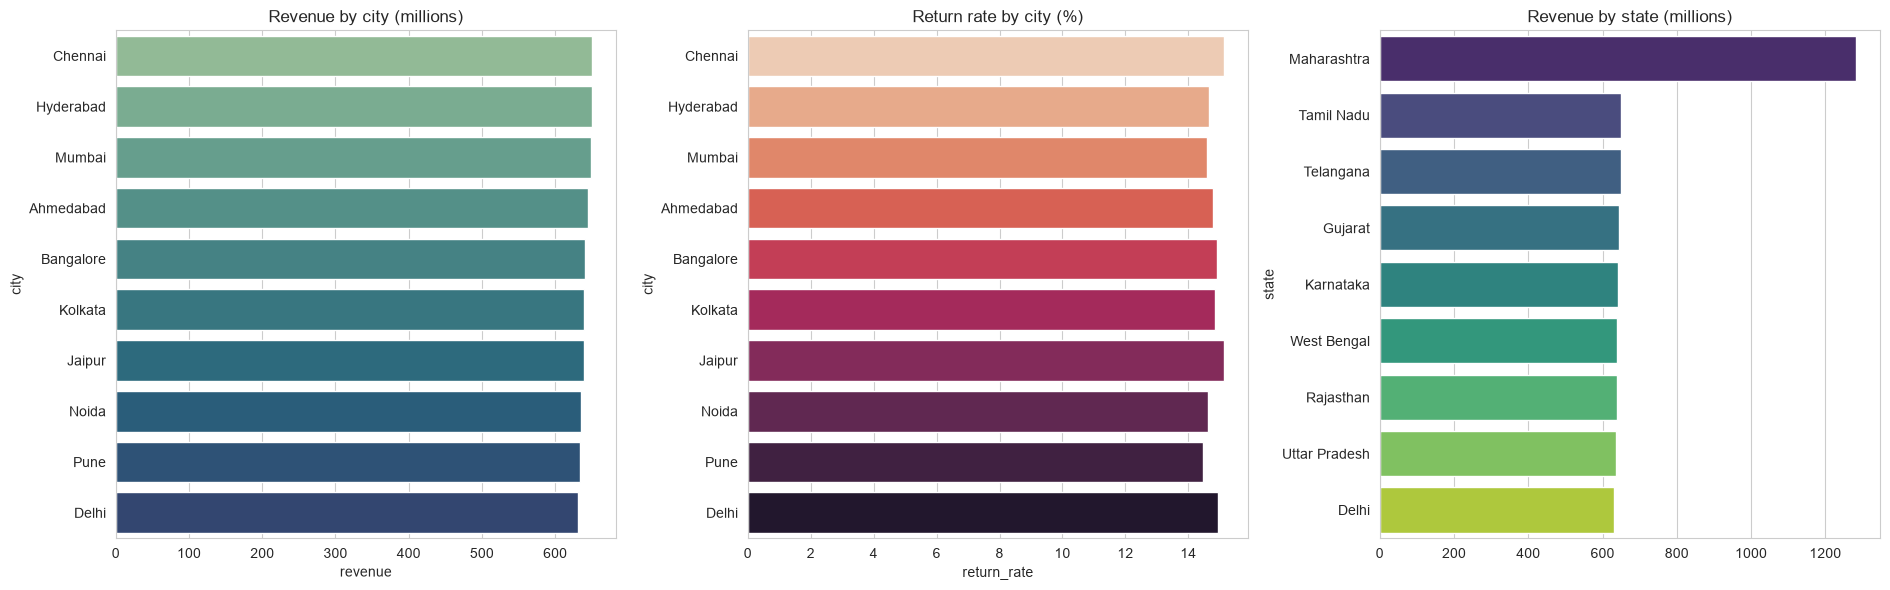

In [41]:
city_table = retail_data.groupby("city").agg(orders=("order_id", "count"), revenue=("final_price", "sum"),
                                             average_order_value=("final_price", "mean"), return_rate=("is_return", "mean"))
city_table["return_rate"] = city_table["return_rate"] * 100
city_table["revenue"] = city_table["revenue"] / 1000000
city_table = city_table.sort_values("revenue", ascending=False)
display(city_table)

state_revenue = retail_data.groupby("state")["final_price"].sum().sort_values(ascending=False) / 1000000

fig, axes = plt.subplots(1, 3, figsize=(19, 6))
sns.barplot(x=city_table["revenue"], y=city_table.index, hue=city_table.index, palette="crest", legend=False, ax=axes[0])
axes[0].set_title("Revenue by city (millions)")
sns.barplot(x=city_table["return_rate"], y=city_table.index, hue=city_table.index, palette="rocket_r", legend=False, ax=axes[1])
axes[1].set_title("Return rate by city (%)")
sns.barplot(x=state_revenue.values, y=state_revenue.index, hue=state_revenue.index, palette="viridis", legend=False, ax=axes[2])
axes[2].set_title("Revenue by state (millions)")

plt.tight_layout()
plt.savefig("outputs/figures/24_city_state.png", bbox_inches="tight")
plt.show()

**Interpretation:**
- Every city gives about one tenth of the revenue, from 631 million (Delhi) to 651 million (Chennai). Average order value is 63,371 (Delhi) to 65,108 (Chennai) and return rate 14.48% (Pune) to 15.14% (Jaipur). These gaps are small, in line with the tests in sections 8.5 and 9.3.
- Maharashtra is the top state (about 1,283 million, 20%) only because it has two cities.
- No city or state stands out in revenue, order value or returns.

### 11.3 Products

,product_category,product_subcategory,orders,revenue,average_unit_price,return_rate
15,Health,Supplements,5657,359.90,"29,992.65",15.08
14,Health,Protein Powder,5668,359.82,"30,003.13",14.54
11,Grocery,Organic Rice,5567,357.44,"30,370.81",14.46
2,Beauty,Shampoo,5578,356.82,"30,217.22",15.24
0,Beauty,Face Cream,5512,354.04,"29,763.88",13.79
16,Health,Vitamins,5533,353.91,"30,424.21",14.87
13,Grocery,Snacks,5548,353.34,"29,825.04",15.23
12,Grocery,Pulses,5477,352.80,"30,118.82",14.92
1,Beauty,Perfume,5423,346.48,"30,193.68",15.25
3,Electronics,Headphones,4265,277.74,"31,102.62",14.28


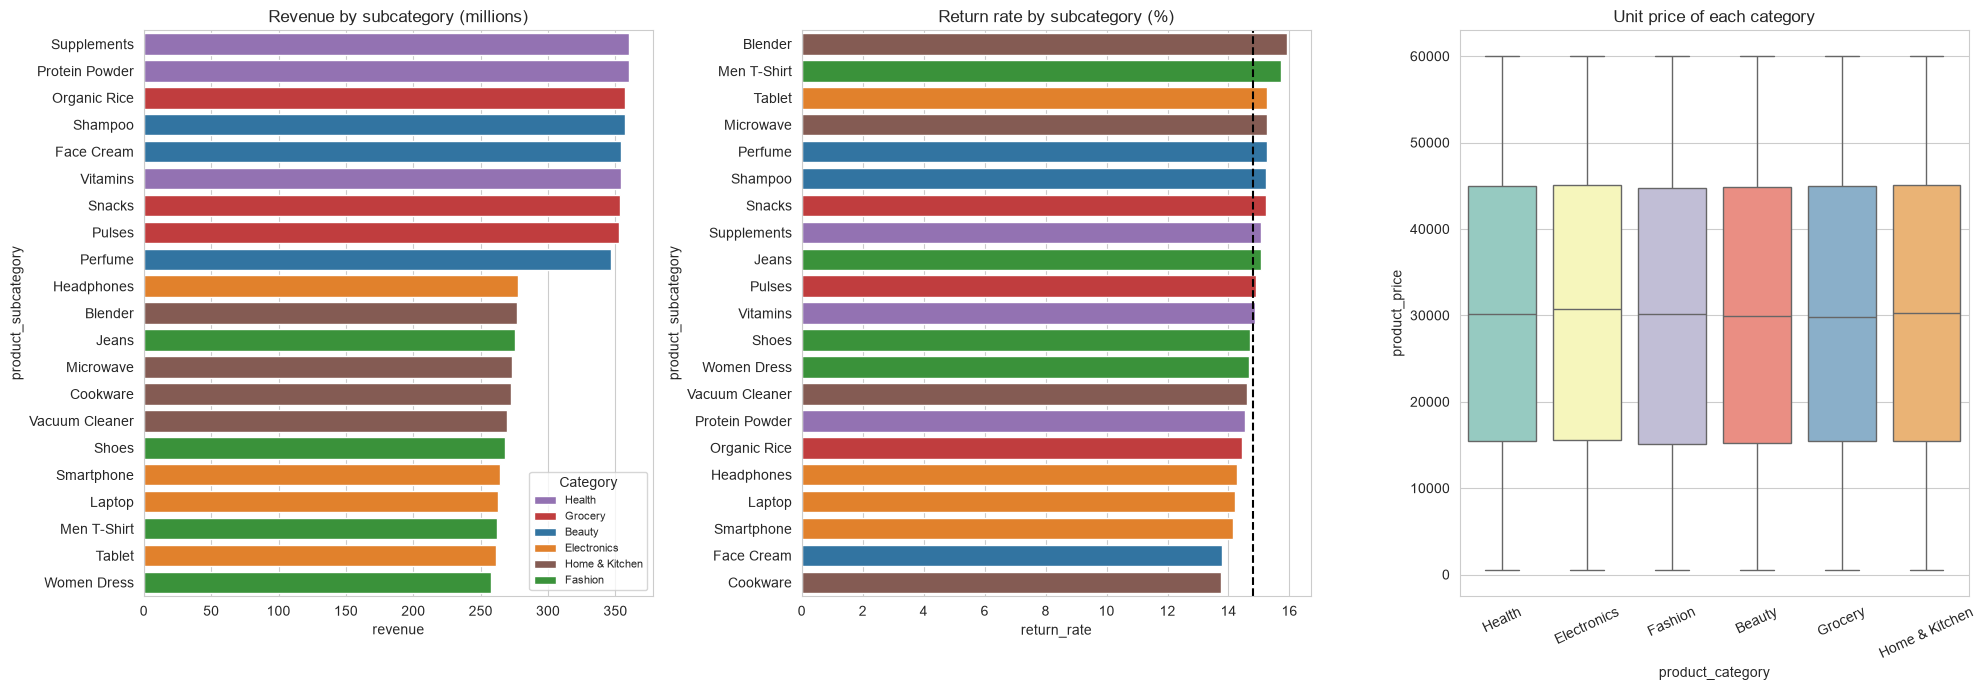

In [42]:
product_table = retail_data.groupby(["product_category", "product_subcategory"]).agg(
    orders=("order_id", "count"), revenue=("final_price", "sum"),
    average_unit_price=("product_price", "mean"), return_rate=("is_return", "mean")).reset_index()
product_table["revenue"] = product_table["revenue"] / 1000000
product_table["return_rate"] = product_table["return_rate"] * 100
product_table = product_table.sort_values("revenue", ascending=False)
display(product_table)

# same colour for the same category in all charts
categories = sorted(retail_data["product_category"].unique())
category_colors = dict(zip(categories, sns.color_palette("tab10", len(categories))))

fig, axes = plt.subplots(1, 3, figsize=(20, 7))
sns.barplot(data=product_table, x="revenue", y="product_subcategory", hue="product_category",
            palette=category_colors, dodge=False, ax=axes[0])
axes[0].set_title("Revenue by subcategory (millions)")
axes[0].legend(title="Category", loc="lower right", fontsize=8)

by_return = product_table.sort_values("return_rate", ascending=False)
sns.barplot(data=by_return, x="return_rate", y="product_subcategory", hue="product_category",
            palette=category_colors, dodge=False, legend=False, ax=axes[1])
axes[1].axvline(retail_data["is_return"].mean() * 100, color="black", linestyle="--")
axes[1].set_title("Return rate by subcategory (%)")

sns.boxplot(data=retail_data, x="product_category", y="product_price", hue="product_category", palette="Set3", legend=False, ax=axes[2])
axes[2].set_title("Unit price of each category")
axes[2].tick_params(axis="x", rotation=25)

plt.tight_layout()
plt.savefig("outputs/figures/25_products.png", bbox_inches="tight")
plt.show()

**Interpretation:**
- Top subcategories by revenue: Supplements (359.9 million), Protein Powder (359.8), Organic Rice (357.4) and Shampoo (356.8). Lowest: Women Dress (257.4), Tablet (261.4) and Laptop (262.6). The top 9 all belong to Health, Grocery and Beauty, which have 3 subcategories each against 4 for the rest, the same reason as in section 5.
- Return rate by subcategory is between 13.75% (Cookware) and 15.91% (Blender), which is within chance (section 9).
- Average unit price is between 29,764 and 31,103 for all 21 subcategories, and the six category boxplots look alike. A laptop priced like a snack is unrealistic, so the data looks artificial and the product prices should not be over-interpreted.

### 11.4 Discounts
Do discounts make customers buy more? Averages per order are compared, because the 0-5% band has six discount values and the others five.

,orders,average_quantity,average_gross_order,average_final_price,average_discount_given,return_rate
discount_band,,,,,,
0-5%,19364,2.51,"75,535.88","73,663.40","1,872.48",14.82
6-10%,16063,2.50,"75,875.86","69,797.06","6,078.80",14.98
11-15%,16151,2.49,"75,225.37","65,423.21","9,802.15",14.84
16-20%,16133,2.51,"75,962.95","62,281.74","13,681.22",14.39
21-25%,16130,2.49,"75,093.46","57,822.95","17,270.51",14.66
26-30%,16159,2.50,"75,199.65","54,141.87","21,057.78",15.17


Total sales before discount (millions): 7548.4
Total discount given (millions): 1131.8 = 14.99 % of sales
Correlation between discount % and quantity: -0.0036


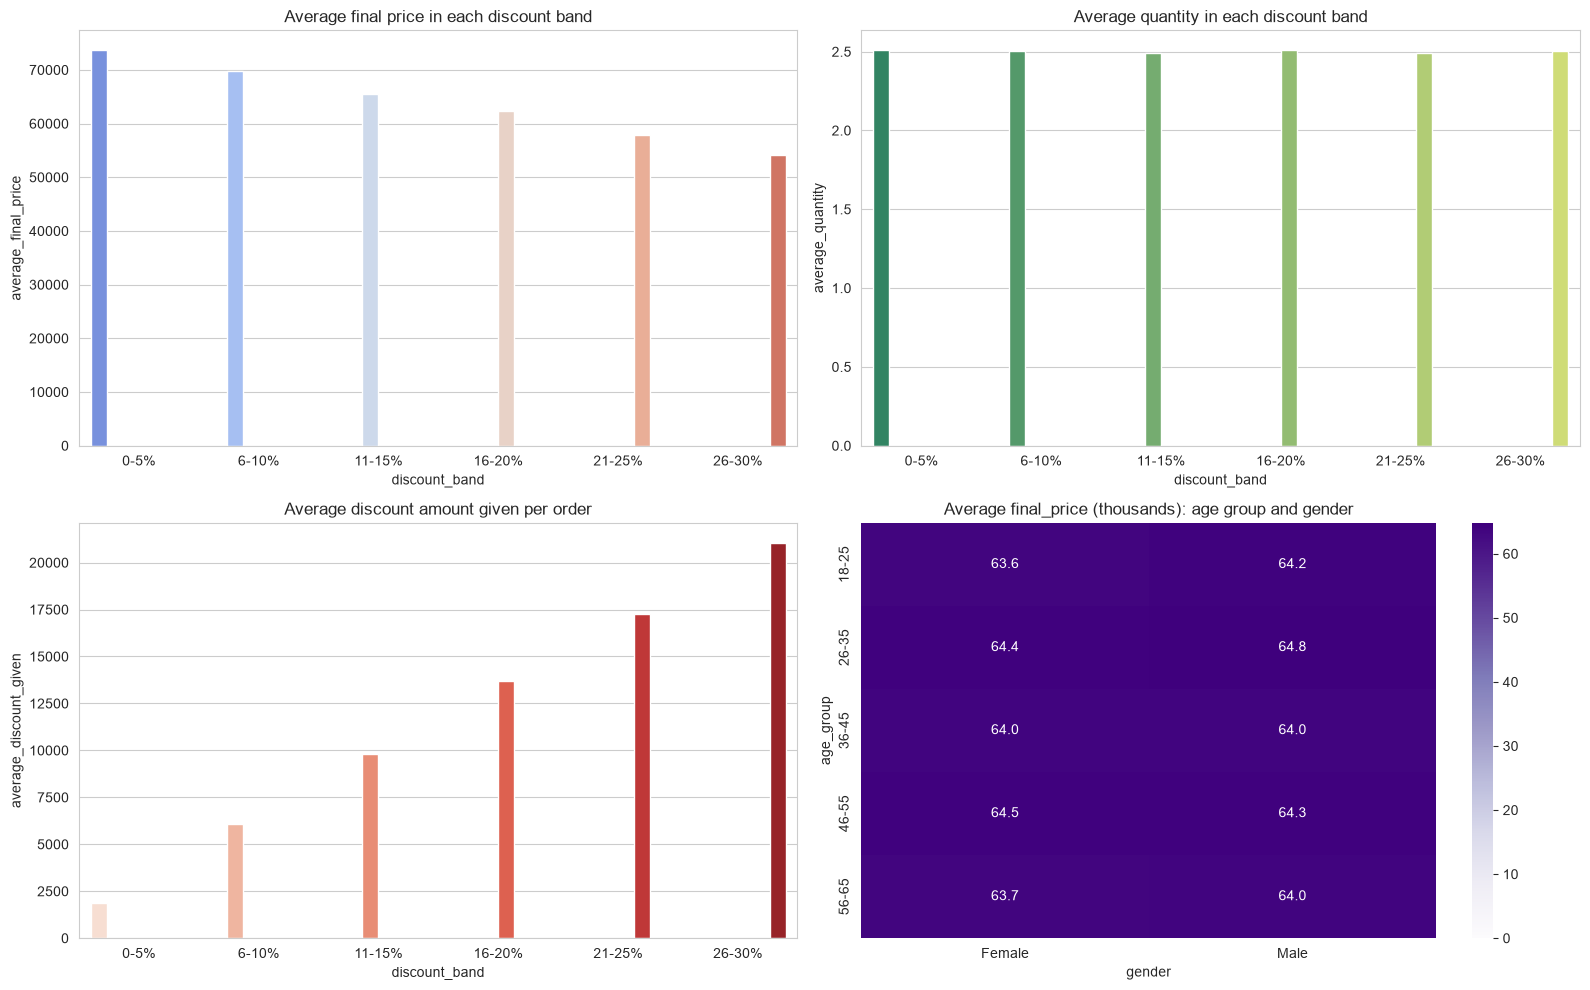

In [43]:
discount_table = retail_data.groupby("discount_band", observed=True).agg(
    orders=("order_id", "count"), average_quantity=("quantity", "mean"), average_gross_order=("gross_amount", "mean"),
    average_final_price=("final_price", "mean"), average_discount_given=("discount_amount", "mean"),
    return_rate=("is_return", "mean"))
discount_table["return_rate"] = discount_table["return_rate"] * 100
display(discount_table)

total_gross = retail_data["gross_amount"].sum()
total_discount = retail_data["discount_amount"].sum()
print("Total sales before discount (millions):", round(total_gross / 1000000, 1))
print("Total discount given (millions):", round(total_discount / 1000000, 1), "=", round(total_discount / total_gross * 100, 2), "% of sales")
print("Correlation between discount % and quantity:", round(retail_data["discount_percentage"].corr(retail_data["quantity"]), 4))

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
sns.barplot(data=discount_table.reset_index(), x="discount_band", y="average_final_price", hue="discount_band",
            palette="coolwarm", legend=False, ax=axes[0, 0])
axes[0, 0].set_title("Average final price in each discount band")
sns.barplot(data=discount_table.reset_index(), x="discount_band", y="average_quantity", hue="discount_band",
            palette="summer", legend=False, ax=axes[0, 1])
axes[0, 1].set_title("Average quantity in each discount band")
sns.barplot(data=discount_table.reset_index(), x="discount_band", y="average_discount_given", hue="discount_band",
            palette="Reds", legend=False, ax=axes[1, 0])
axes[1, 0].set_title("Average discount amount given per order")

pivot_ag = retail_data.pivot_table(values="final_price", index="age_group", columns="gender", aggfunc="mean", observed=True)
sns.heatmap(pivot_ag / 1000, annot=True, fmt=".1f", cmap="Purples", vmin=0, ax=axes[1, 1])
axes[1, 1].set_title("Average final_price (thousands): age group and gender")

plt.tight_layout()
plt.savefig("outputs/figures/26_discounts_age_gender.png", bbox_inches="tight")
plt.show()

**Interpretation:**
- Total sales before discount are 7,548.4 million, the discount given is 1,131.8 million (14.99% of sales) and revenue after discount is 6,416.6 million.
- Discounts did not increase the quantity: average quantity is 2.49 to 2.51 in every band and the correlation between discount and quantity is -0.0036.
- The average final price falls from 73,663 (0-5%) to 54,142 (26-30%), which is 26.5% lower, while the average discount given per order rises from 1,872 to 21,058 (about 11 times). The return rate changes little (14.4% to 15.2%).
- The 0-5% band has more orders (19,364 against about 16,100) only because it covers six discount values.
- The data has only placed orders, so it cannot show whether discounts bring customers who would not have bought otherwise.
- In the age and gender heatmap every cell is between 63.6 and 64.8 thousand, so there is no real difference.

## 12. Findings and Conclusion

### 12.1 Key Numbers

In [44]:
quick_numbers = pd.Series({
    "Orders": f"{len(retail_data):,}",
    "Period": f"{retail_data['order_date'].min().date()} to {retail_data['order_date'].max().date()}",
    "Total revenue (millions)": f"{retail_data['final_price'].sum() / 1000000:,.1f}",
    "Average order value": f"{retail_data['final_price'].mean():,.0f}",
    "Median order value": f"{retail_data['final_price'].median():,.0f}",
    "Discount given (% of sales)": f"{retail_data['discount_amount'].sum() / retail_data['gross_amount'].sum() * 100:.2f}%",
    "Return rate": f"{retail_data['is_return'].mean() * 100:.2f}%",
    "Outlier orders in final_price": f"{retail_data['is_outlier'].sum():,}",
}, name="value").to_frame()
quick_numbers

,value
Orders,"100,000"
Period,2023-01-01 to 2025-12-30
Total revenue (millions),"6,416.6"
Average order value,"64,166"
Median order value,"49,752"
Discount given (% of sales),14.99%
Return rate,14.81%
Outlier orders in final_price,"1,335"


### 12.2 Main Findings
1. The data is clean: no missing values, duplicates, spacing or spelling problems, and all range checks passed.
2. `final_price` is calculated from price, quantity and discount, so its strong correlations with them are expected.
3. Age, price, quantity, discount and delivery days are evenly spread. `final_price` is the only right-skewed column (skewness 0.93).
4. Only `final_price` has outliers: 1,335 orders (1.3%), all with quantity 4, a high price and a low discount. They are real orders, and capping changes the average by only 0.3%.
5. Segment, gender, age, city, payment method and shipping type make no real difference to order value (all p-values above 0.05).
6. The return rate is 14.81% and similar in every group. No column is related to returns.
7. Express shipping takes the same time as Standard (5.50 and 5.51 days).
8. Discounts cost about 15% of sales without increasing quantity. Order value is highest when the discount is lowest.
9. There is no clear trend or seasonality across the three years, and cities, weekdays and subcategories are all similar.

### 12.3 Expected Patterns vs Observed Results
- **Matched:** the return rate is about 15% (14.81%), discounts are spread evenly from 0 to 30%, price and quantity are strongly linked to `final_price`, and age is not related to spending.
- **Different:** `product_price` is not skewed, `final_price` does not have very high kurtosis, Regular is not the largest segment, Electronics has neither the most orders nor the most returns, Express is not faster, Premium customers do not clearly spend more, moderate discounts do not give the highest value, and longer delivery does not increase returns.

### 12.4 Suggestions
- Review the discount policy. Discounts cost about 15% of sales without increasing the quantity.
- Do not target customers by segment, gender, age or city based on this data, as no differences were found.
- Check the Express service. It delivers in the same time as Standard.
- Collect the reason for each return, because none of the current columns explains returns.

### 12.5 Limitations
- The data looks artificially generated (flat distributions, prices unrelated to the product, zero correlation between inputs), so the results apply to this dataset only.
- Each customer has one order, so repeat purchases cannot be studied.
- There is no cost or profit column, so revenue is not profit. The currency is also not given.
- The analysis shows relationships, not causes.

### 12.6 Conclusion
The retail data was checked, cleaned and analysed with univariate, bivariate and multivariate methods, outlier detection with capping, correlation, ANOVA and chi-square tests, and additional trend analysis. Order value depends on the price, quantity and discount of the order, not on who the customer is. Returns are about 15% everywhere and are not linked to any column, and discounts lowered revenue per order without raising the quantity. As the data looks artificial, the analysis should be repeated on real data to confirm these patterns. The cleaned data (`data/Processed_dataset.csv`) and the charts (`outputs/figures/`) are saved for further work such as modelling.